<h3 style="color:yellow";> 1. Load Packages </h3>


In [46]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

<h3 style="color:yellow";> 2. Load Dataset </h3>

Load KNHANES survey data (2020–2024) across five annual CSV files and inspect shape, column names, and first rows.

In [47]:
df_hn24 = pd.read_csv('../csv/HN24_all.csv', low_memory=False) 
df_hn23 = pd.read_csv('../csv/HN23_all.csv', low_memory=False)
df_hn22 = pd.read_csv('../csv/HN22_all.csv', low_memory=False)
df_hn21 = pd.read_csv('../csv/HN21_all.csv', low_memory=False)
df_hn20 = pd.read_csv('../csv/HN20_all.csv', low_memory=False)


df = pd.concat([df_hn20, df_hn21, df_hn22, df_hn23, df_hn24], ignore_index=True)
print(df.shape)
print(df.columns.tolist())
print(df.head())


(34640, 1188)
['mod_d', 'ID', 'ID_fam', 'year', 'region', 'town_t', 'apt_t', 'psu', 'sex', 'age', 'age_month', 'incm', 'ho_incm', 'incm5', 'ho_incm5', 'edu', 'occp', 'wt_hs', 'wt_itvex', 'wt_oe', 'wt_ntr', 'wt_tot', 'wt_oent', 'kstrata', 'cfam', 'genertn', 'allownc', 'house', 'live_t', 'ainc_unit1', 'ainc_1', 'ainc', 'marri_1', 'marri_2', 'fam_rela', 'tins', 'npins', 'ID_F', 'ID_M', 'D_1_1', 'D_2_1', 'D_2_wk', 'DI1_dg', 'DI1_ag', 'DI1_pr', 'DI1_pt', 'DI1_2', 'DI2_dg', 'DI2_ag', 'DI2_pr', 'DI2_pt', 'DI2_2', 'DI3_dg', 'DI3_ag', 'DI3_pr', 'DI3_pt', 'DI3_2', 'DI4_dg', 'DI4_pr', 'DI4_pt', 'DI5_dg', 'DI5_ag', 'DI5_pr', 'DI5_pt', 'DI6_dg', 'DI6_ag', 'DI6_pr', 'DI6_pt', 'DM1_dg', 'DM1_pr', 'DM1_pt', 'DM2_dg', 'DM2_ag', 'DM2_pr', 'DM2_pt', 'DM3_dg', 'DM3_ag', 'DM3_pr', 'DM3_pt', 'DM4_dg', 'DM4_ag', 'DM4_pr', 'DM4_pt', 'DJ2_dg', 'DJ2_ag', 'DJ2_pr', 'DJ2_pt', 'DJ4_dg', 'DJ4_ag', 'DJ4_pr', 'DJ4_pt', 'DJ4_3', 'DE2_dg', 'DE2_ag', 'DE2_pr', 'DE2_pt', 'DE1_dg', 'DE1_ag', 'DE1_pr', 'DE1_pt', 'DE1_3', '

<h3 style="color:yellow";> 2.1 Feature Selection & Age Filtering </h3>

Full list of candidate variables drawn from KNHANES. Variables excluded from the final feature set are noted in the code cell below.

| Variable | Type/Format | Description | Values / Unit |
|---|---|---|---|
| `age` | N(3) | Chronological Age (top-coded at 80) | Continuous (1–79); 80 = ≥80 years |
| `sex` | N(1) | Biological Sex | 1: Male, 2: Female |
| `region` | N(2) | Area of Residence (17 Regional Provinces) | Nominal (1: Seoul … 17: Jeju) |
| `town_t` | N(1) | Area Classification (Urban vs. Rural) | 1: Dong (Urban), 2: Eup/Myeon (Rural) |
| `edu` | N(1) | Educational Attainment | 1: ≤ Elementary, 2: Middle, 3: High school, 4: ≥ College |
| `ho_incm` | N(1) | Household Income Quartile | 1: Low, 2: Lower-mid, 3: Upper-mid, 4: High |
| `marri_1` | N(1) | Marital Status | 1: Married, 2: Unmarried |
| `occp` | N(1) | Occupation | 1: Managers/Professionals, 2: Clerks, 3: Service/Sales, 4: Agricultural, 5: Craft/Machine, 6: Elementary, 7: Unemployed |
| `house` | N(1) | Home Ownership | 1: No, 2: Owns 1, 3: Owns ≥2, 9: Missing |
| `cfam` | N(1) | Household Size | 1: 1 person … 6: ≥6 people |
| `live_t` | N(1) | Dwelling Type | 1: Detached, 2: Apartment, 3: Townhouse, 4: Other |
| `tins` | N(2) | Health Insurance Category | 10: NHI Regional, 20: NHI Workplace, 30: Medical Aid |
| `DE1_dg` | N(1) | Diabetes Mellitus (Doctor Diagnosis) | 0: No, 1: Yes, 8: N/A, 9: Missing → used to derive `diabetes` |
| `HE_HbA1c` | N(8.1) | Glycated Hemoglobin (HbA1c) | Continuous / % → used to derive `diabetes` |
| `HE_BMI` | N(8.1) | Body Mass Index | Continuous / kg/m² |
| `HE_crea` | N(8.2) | Blood Creatinine | Continuous / mg/dL → used to derive `eGFR` |
| `HE_Uacid` | N(4.1) | Blood Uric Acid | Continuous / mg/dL |
| `HE_TG` | N(4) | Serum Triglycerides | Continuous / mg/dL |
| `HE_sbp` | N(8.1) | Mean Systolic Blood Pressure | Continuous / mmHg → also used to derive `hypertension` |
| `HE_dbp` | N(8.1) | Mean Diastolic Blood Pressure | Continuous / mmHg → also used to derive `hypertension` |
| `HE_Upro` | N(1) | Urine Protein (Proteinuria) | 0: Negative, 1: Trace, 2: +1, 3: +2, 4: +3, 5: +4 |
| `HE_Ucrea` | N(8.2) | Urine Creatinine | Continuous / mg/dL |
| `sm_presnt` | N(1) | Current Smoking Status | 0: Non-smoker, 1: Current smoker |
| `BD1` | N(1) | Current Alcohol Drinking Status | 1: Yes, 2: No |
| `pa_aerobic` | N(1) | Aerobic Physical Activity Adherence | 0: Non-adherent, 1: Adherent |
| `BP1` | N(1) | Perceived Stress Level | 1: Extreme, 2: Severe, 3: Moderate, 4: Very low |
| `L_BR_FQ` | N(1) | Breakfast Consumption Frequency | Ordinal (daily → rarely) |
| `N_CA` | N(8.2) | Daily Calcium Intake (24-hr recall) | Continuous / mg |
| `N_EN` | N(8.2) | Daily Total Energy Intake | Continuous / kcal |
| `N_NA` | N(8.2) | Daily Total Sodium Intake | Continuous / mg |
| `N_PROT` | N(8.2) | Daily Total Protein Intake | Continuous / g |
| `N_TDF` | N(8.2) | Daily Total Dietary Fiber Intake | Continuous / g |
| `N_SUGAR` | N(8.2) | Daily Total Sugar Intake | Continuous / g |
| `LS_VEG1` | N(8.2) | Daily Vegetable Intake (excl. Kimchi) | Continuous / g |
| `LS_FRUIT` | N(8.2) | Daily Fresh Fruit Intake | Continuous / g |
| `O_pain` | N(1) | Dental Pain / Discomfort | 0: No, 1: Yes |
| `MO4_00` | N(1) | Dental Visit in Past Year | 0: No, 1: Yes |
| `BM1_0` | N(1) | Toothbrushing Yesterday | 0: No, 1: Yes |
| `BM1_1`–`BM1_8` | N(1) × 8 | Brushing Occasions Yesterday (each time-slot) | 0: No, 1: Yes → summed into `brush_freq` |
| `O_TC` | N(2) | Total Natural Teeth Present (incl. 3rd molars) | Continuous / count — **target variable** |

**Derived features** (computed from the raw columns above; replace or supplement their sources in `feature_cols`):

| Derived Variable | Source Columns | Description | Values / Unit |
|---|---|---|---|
| `eGFR` | `HE_crea`, `age`, `sex` | Estimated GFR — CKD-EPI 2021 creatinine equation | Continuous / mL/min/1.73m² |
| `diabetes` | `DE1_dg`, `HE_HbA1c` | Diabetes: doctor diagnosis OR HbA1c ≥ 6.5% | 0: No, 1: Yes |
| `hypertension` | `HE_sbp`, `HE_dbp` | Hypertension: SBP ≥ 140 OR DBP ≥ 90 mmHg | 0: No, 1: Yes |
| `brush_freq` | `BM1_1`–`BM1_8` | Count of toothbrushing occasions yesterday | Continuous (0–8) |

In [48]:
raw_columns = [
    'year', 'age', 'sex',
    # SES / demographics
    'ho_incm', 'edu', 'occp', 'marri_1', 'house', 'cfam', 'live_t', 'tins',
    'region', 'town_t',
    # Disease diagnoses (sentinel 8/9 → NaN)
    'DE1_dg',
    # Lab values
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp',
    # Urinalysis
    'HE_Upro', 'HE_Ucrea',
    # Lifestyle
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1',
    # Secondhand smoke exposure, indoor workplace (sentinel 8/9 → NaN)
    'BS12_1',
    # Dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ',
    # Dental
    'O_pain',
    'MO4_00',
    'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8',
    # Target
    'O_TC',
    # survey design (not modelled; weighted inference only)
    'wt_itvex', 'psu', 'kstrata',
]
# OR1        excluded: equals 1 for every row that passed the O_TC filter
# HE_obe    excluded: redundant with HE_BMI
# DI1_dg    excluded: using continuous HE_sbp / HE_dbp instead
# DI4_dg    excluded: -inf sentinel in raw data, unreliable
# DE1_4     excluded: >80% missing, insufficient coverage for modelling
# DL1_dg    excluded: atopic dermatitis — no clinical link to tooth loss
# DJ4_dg    excluded: asthma — indirect link not measurable without inhaler data
# HE_chol   excluded: no significant independent tooth loss mechanism (p=0.90)
# HE_HDL_st2 excluded: not significant (p=0.73), no independent tooth loss mechanism
# HE_wc     excluded: collinear with HE_BMI (VIF 5.81 vs 5.11); HE_BMI retained as standard measure
# HE_glu    excluded: collinear with HE_HbA1c / diabetes (both measure glycaemic control); redundant
# BS3_1     excluded: 62.1% missing (N/A for age < 19)
# BS6_2/BS6_3 excluded: HN20-24 columns are continuous quantity vars (8888/888 = never-used ~72%), not the nominal use variable
# BD2_1     excluded: 42.4% missing (N/A for non-drinkers)
# LW_ms     excluded: 48.3% missing (N/A for males); post_menopause feature dropped
# N_EN      excluded: total energy intake — collinear with the component dietary intakes (high VIF); dropped from both models

age_threshold = 65
df_subset = df[raw_columns].copy()
df_subset = df_subset[df_subset['age'] >= age_threshold]
print(df_subset.shape)
print(df_subset.columns.tolist())

(9003, 51)
['year', 'age', 'sex', 'ho_incm', 'edu', 'occp', 'marri_1', 'house', 'cfam', 'live_t', 'tins', 'region', 'town_t', 'DE1_dg', 'HE_HbA1c', 'HE_BMI', 'HE_crea', 'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_Upro', 'HE_Ucrea', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR', 'L_BR_FQ', 'O_pain', 'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8', 'O_TC', 'wt_itvex', 'psu', 'kstrata']


<h3 style="color:yellow";> 2.2 EDA - Age Distribution </h3>

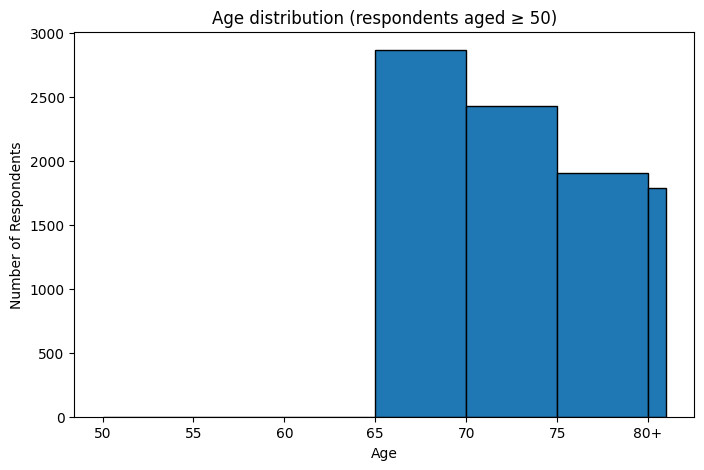

In [49]:
plt.figure(figsize=(8,5))
bins = list(range(50,81,5)) + [81]
plt.hist(df_subset['age'], bins=bins, edgecolor='black')
plt.xlabel("Age")
plt.ylabel("Number of Respondents")
plt.title("Age distribution (respondents aged ≥ 50)")
ticks = list(range(50,81,5))
labels = [str(t) for t in ticks[:-1] + ['80+']]
plt.xticks(ticks, labels)
plt.show()

<h2 style="color:#FFA500";> 3. Target Variable — Cleaning & Binary Label </h2>

Clean `O_TC` (total tooth count) and produce a binary classification target:

- **a.** Most missing `O_TC` entries appear as `NaN`, but the 2024 file (HN24) encodes them as a `-1.80E+308` overflow sentinel that parses to `-inf` rather than `NaN`.
- **b.** `pd.to_numeric(..., errors='coerce')` coerces any remaining non-numeric values to `NaN`; the `±inf` sentinels are then replaced explicitly with `NaN`.
- **c.** Rows where `O_TC` is `NaN` are dropped; only records with a valid tooth count are kept.
- **d.** Binary label `O_TC_`: `1` if tooth count < 20 (functionally impaired), `0` otherwise.
- **e.** Class imbalance is assessed via the ratio of majority (0) to minority (1) class counts.


In [50]:
print(df_subset[pd.to_numeric(df_subset['O_TC'], errors='coerce').isna()]['O_TC'].unique())
# ^ finds all non numeric codes in the O_TC column and displays what those 'errors' were, in this case it 
# was ['-1.80E+308']

df_subset['O_TC'] = pd.to_numeric(df_subset['O_TC'], errors='coerce')
# -1.80E+308 overflows float64 and becomes -inf (not NaN), so replace both infinities explicitly
df_subset['O_TC'] = df_subset['O_TC'].replace([np.inf, -np.inf], np.nan)

before_drop = len(df_subset)
df_subset = df_subset.dropna(subset=['O_TC'])
print(f"Rows dropped (NaN O_TC): {before_drop - len(df_subset)}")
# ^ to know how many rows were dropped because of NaN; not required to the code --  just to visualize

df_subset['O_TC_'] = (df_subset['O_TC'] < 20).astype(int)
# ^ a lot of research papers determined O_TC value below 20 is considered impactful to the normal
# chewing and digestion problems. 
# "astype(int) --> converts True = 1 and False = 0"

label_counts    = df_subset['O_TC_'].value_counts()
# ^ counts how many values are there in the new 'O_TC_' column of 0s and 1s 
label_0         = label_counts[0]
label_1         = label_counts[1]

print(f"Age filter: >= {age_threshold}")
print(f"Label 0 (≥20 teeth): {label_0}")
print(f"Label 1 (<20 teeth): {label_1}")
print(df_subset['O_TC'].value_counts(dropna=False).head(20))

print(f"NaN count: {df_subset['O_TC'].isna().sum()}")

[nan]
Rows dropped (NaN O_TC): 1299
Age filter: >= 65
Label 0 (≥20 teeth): 4346
Label 1 (<20 teeth): 3358
O_TC
0.0     764
28.0    634
27.0    500
26.0    499
25.0    450
24.0    448
23.0    393
22.0    364
21.0    312
20.0    265
19.0    240
18.0    191
29.0    189
16.0    183
17.0    180
15.0    139
4.0     138
12.0    138
14.0    137
30.0    131
Name: count, dtype: int64
NaN count: 0


<h3 style="color:yellow";> 3.1 O_TC Count </h3>

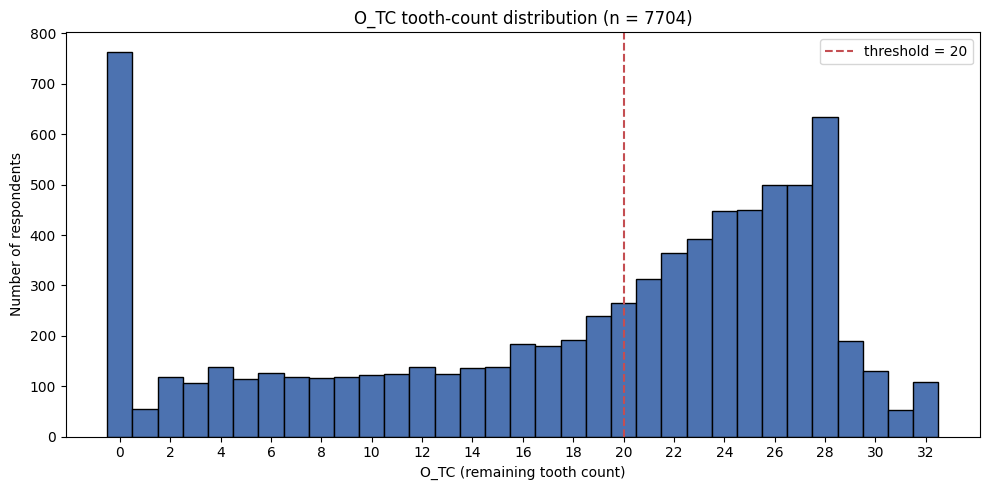

In [51]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df_subset['O_TC'], bins=range(0, 34), color='#4C72B0',
        edgecolor='black', align='left')
ax.set_xlabel('O_TC (remaining tooth count)')
ax.set_ylabel('Number of respondents')
ax.set_title(f'O_TC tooth-count distribution (n = {len(df_subset)})')
ax.set_xticks(range(0, 33, 2))


ax.axvline(20, color='#C44E52', linestyle='--', linewidth=1.5,
           label=f'threshold = 20')
ax.legend()

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 3.2 Class imbalance </h3>

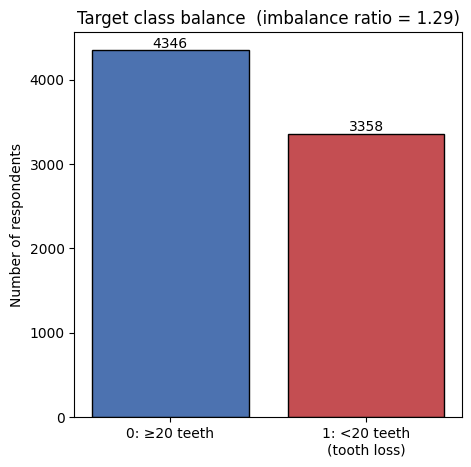

In [52]:
counts = df_subset['O_TC_'].value_counts().sort_index()

plt.figure(figsize=(5, 5))
bars = plt.bar(
    ['0: ≥20 teeth', '1: <20 teeth\n(tooth loss)'],
    counts.values,
    color=['#4C72B0', '#C44E52'],
    edgecolor='black'
)
plt.ylabel('Number of respondents')
plt.title(f'Target class balance  (imbalance ratio = {counts[0] / counts[1]:.2f})')

# annotate each bar with its count
for bar, n in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, n, str(n), ha='center', va='bottom')

plt.show()

<h2 style="color:#FFA500";> 4. Missing Value Audit & Invalid-Code Replacement </h2>

Survey responses use reserved codes (8, 9, 88, 99, 888, 999) for refusals and non-applicable items — these are **not** true values and must be replaced with `NaN` before modelling.

- **Disease columns** (`DE1_dg`): replace invalid codes (8 = N/A, 9 = missing) with `NaN`.
- **Survey columns** (`edu`, `ho_incm`, `occp`, `marri_1`, `sm_presnt`, `BP1`, `O_pain`, `MO4_00`, `BM1_0`–`BM1_8`, `BM2_1`, `BM2_3`, etc.): replace invalid codes with `NaN`.
- **Lab columns** (`HE_HbA1c`, `HE_BMI`, `HE_crea`, `HE_Uacid`, `HE_TG`, `HE_sbp`, `HE_dbp`, `HE_Ucrea`): coerce to numeric and nullify sentinel magnitudes (≥ 1e10).
- Creatinine values ≤ 0 are physiologically impossible and are also nullified.

In [53]:
# Disease diagnoses: 8 = not applicable (children/adolescents), 9 = refused/missing
disease_cols = ['DE1_dg']

# Survey ordinal / binary: 8 = not applicable, 9 = refused/missing
# BD1 (current alcohol drinking status: 1=yes, 2=no) uses 8 as N/A
# HE_Upro (proteinuria): 9 = missing (valid values 0–5)
# O_pain: dental pain perception; 0=no pain, 1=pain
# MO4_00 (dental visit past year): 9 = missing
# BM1_0 (toothbrushing yesterday): 9 = missing
# BM1_1–BM1_8 (brushing timing): 8 = N/A (if BM1_0 == 0), 9 = missing
# BS12_1 (indoor secondhand smoke at workplace, past week): 1=yes, 2=no; 8=N/A, 9=missing
survey_cols = ['edu', 'ho_incm', 'occp', 'marri_1', 'house', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'L_BR_FQ', 'HE_Upro', 'O_pain',
               'MO4_00', 'BM1_0', 'BM1_1', 'BM1_2', 'BM1_3', 'BM1_4', 'BM1_5', 'BM1_6', 'BM1_7', 'BM1_8']

# Lab continuous: coerce + overflow-sentinel removal (large float placeholders → NaN)
lab_cols = [
    'HE_HbA1c', 'HE_BMI', 'HE_crea',
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp',
    'HE_Ucrea',
]

# Dietary continuous
diet_cols = ['N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR']

df_subset[disease_cols] = df_subset[disease_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace({8: np.nan, 9: np.nan, 88: np.nan, 99: np.nan})
df_subset[survey_cols]  = df_subset[survey_cols].replace([np.inf, -np.inf], np.nan)

all_lab = lab_cols + diet_cols
df_subset[all_lab] = df_subset[all_lab].apply(pd.to_numeric, errors='coerce')
df_subset[all_lab] = df_subset[all_lab].where(df_subset[all_lab].abs() < 1e10, np.nan)

df_subset.loc[df_subset['HE_crea'] <= 0, 'HE_crea'] = np.nan

# D13: nominal/count cols outside survey_cols still carried sentinels
# (verified in data: tins has 99, live_t has 9, all three have a stray -inf)
df_subset[['cfam', 'tins', 'live_t']] = df_subset[['cfam', 'tins', 'live_t']].replace([np.inf, -np.inf], np.nan)
df_subset['tins']   = df_subset['tins'].replace({99: np.nan})   # 99 = missing (valid: 10/20/30)
df_subset['live_t'] = df_subset['live_t'].replace({9: np.nan})  # 9 = missing (valid: 1-4)
df_subset['cfam']   = df_subset['cfam'].replace({9: np.nan})    # 9 = missing sentinel (valid: 1-6)
# region (1-17) and town_t (1/2): verified clean, no sentinel codes

print("NaN counts per column after cleaning:")
total = len(df_subset)
for col in disease_cols + survey_cols + lab_cols + diet_cols:
    count = df_subset[col].isna().sum()
    pct   = (count / total) * 100
    print(f"  {col:<15}: {count:>5}  ({pct:.1f}%)")

NaN counts per column after cleaning:
  DE1_dg         :     6  (0.1%)
  edu            :   677  (8.8%)
  ho_incm        :    53  (0.7%)
  occp           :   875  (11.4%)
  marri_1        :     1  (0.0%)
  house          :     9  (0.1%)
  sm_presnt      :   272  (3.5%)
  BD1            :   249  (3.2%)
  pa_aerobic     :   900  (11.7%)
  BP1            :   278  (3.6%)
  BS12_1         :   271  (3.5%)
  L_BR_FQ        :   596  (7.7%)
  HE_Upro        :   182  (2.4%)
  O_pain         :     0  (0.0%)
  MO4_00         :   277  (3.6%)
  BM1_0          :   274  (3.6%)
  BM1_1          :   527  (6.8%)
  BM1_2          :   527  (6.8%)
  BM1_3          :   527  (6.8%)
  BM1_4          :   527  (6.8%)
  BM1_5          :   527  (6.8%)
  BM1_6          :   527  (6.8%)
  BM1_7          :   527  (6.8%)
  BM1_8          :   527  (6.8%)
  HE_HbA1c       :   314  (4.1%)
  HE_BMI         :   295  (3.8%)
  HE_crea        :   300  (3.9%)
  HE_Uacid       :   303  (3.9%)
  HE_TG          :   300  (3.9%)
  H

<h3 style="color:yellow";> 4.1 NaN Count </h3>

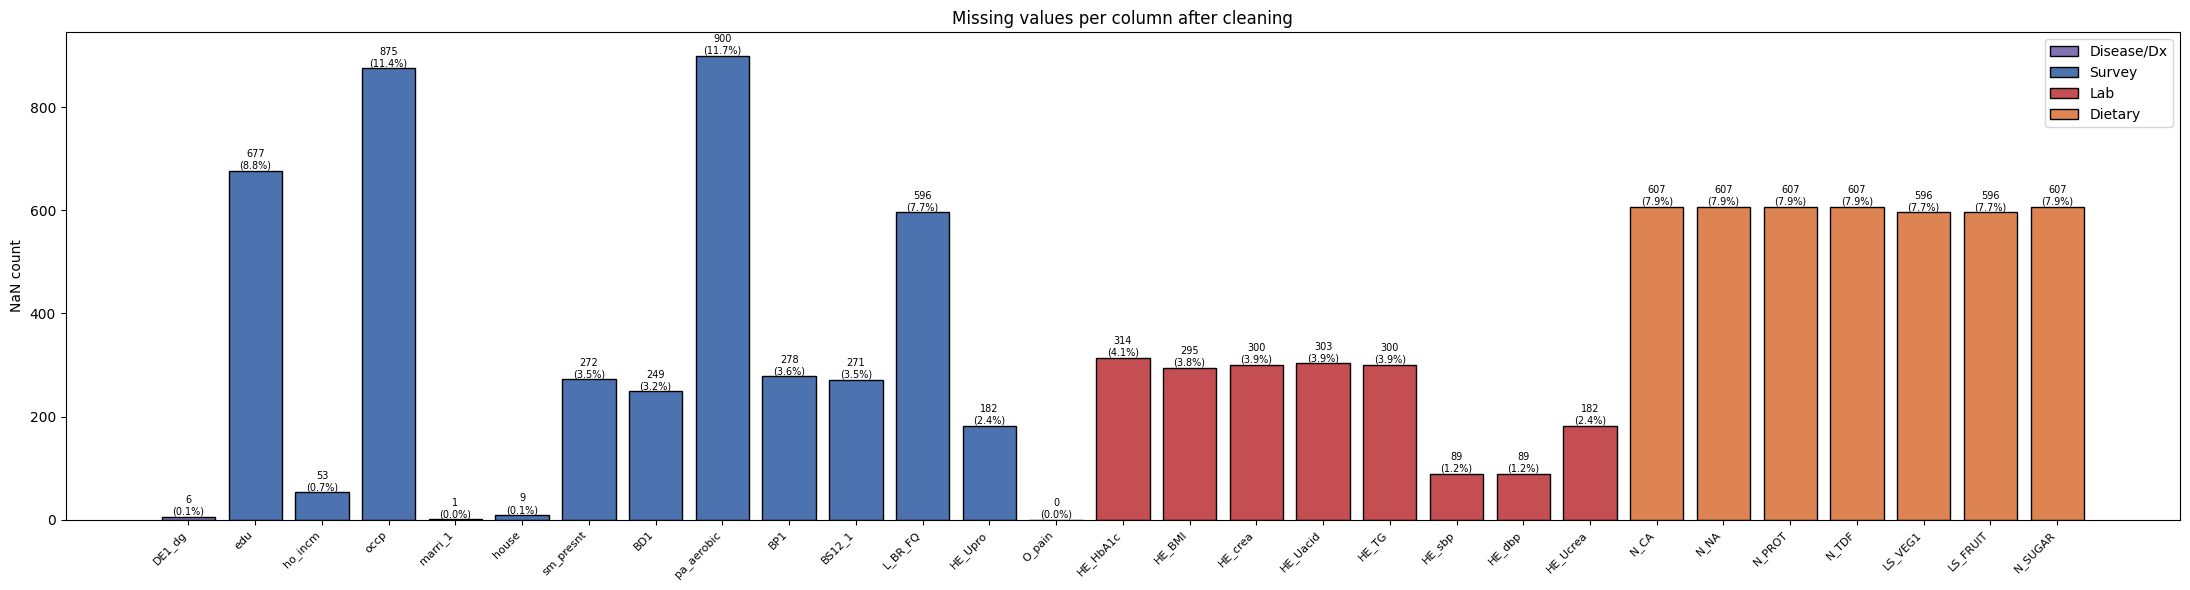

In [54]:
disease_cols_audit = ['DE1_dg']
survey_cols_audit  = ['edu', 'ho_incm', 'occp', 'marri_1', 'house', 'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'BS12_1', 'L_BR_FQ', 'HE_Upro', 'O_pain']
lab_cols_audit     = ['HE_HbA1c', 'HE_BMI', 'HE_crea', 'HE_Uacid',
                      'HE_TG', 'HE_sbp', 'HE_dbp', 'HE_Ucrea']
diet_cols_audit    = ['N_CA','N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR']

audit_cols = disease_cols_audit + survey_cols_audit + lab_cols_audit + diet_cols_audit

na_count = df_subset[audit_cols].isna().sum()
na_pct   = na_count / len(df_subset) * 100

COLOR_MAP = {
    **{c: '#8172B2' for c in disease_cols_audit},
    **{c: '#4C72B0' for c in survey_cols_audit},
    **{c: '#C44E52' for c in lab_cols_audit},
    **{c: '#DD8452' for c in diet_cols_audit},
}
colors = [COLOR_MAP[c] for c in audit_cols]

fig, ax = plt.subplots(figsize=(22, 6))
bars = ax.bar(audit_cols, na_count.values, color=colors, edgecolor='black')

ax.set_ylabel('NaN count')
ax.set_title('Missing values per column after cleaning')
ax.set_xticks(range(len(audit_cols)))
ax.set_xticklabels(audit_cols, rotation=45, ha='right', fontsize=8)

for bar, n, p in zip(bars, na_count.values, na_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n,
            f'{n}\n({p:.1f}%)', ha='center', va='bottom', fontsize=7)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#8172B2', edgecolor='black', label='Disease/Dx'),
    Patch(facecolor='#4C72B0', edgecolor='black', label='Survey'),
    Patch(facecolor='#C44E52', edgecolor='black', label='Lab'),
    Patch(facecolor='#DD8452', edgecolor='black', label='Dietary'),
])
plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 4.2 Derived Feature — eGFR (CKD-EPI 2021) </h3>

Replace raw serum creatinine with estimated Glomerular Filtration Rate (eGFR) using the **CKD-EPI 2021 creatinine equation**. eGFR is a more clinically interpretable measure of kidney function than creatinine alone and reduces the sex-dependence of the raw value.

`HE_crea` is dropped after the derivation; `sex` is retained as a model feature and inferential covariate.

2021 CKD-EPI Creatinine Equation
The 2021 CKD-EPI eGFRcr equation estimates GFR using age, sex, and serum creatinine.2

The equation can be expressed as a single equation:

<h4 style="color:#7FDBFF";> eGFR = 142 × min(SCr/κ, 1)^α × max(SCr/κ, 1)^(-1.200) × 0.9938^Age × 1.012 (if female) </h4>

Abbreviations/units

-   eGFR = estimated GFR in mL/min/1.73 m2
-   SCr = standardized serum creatinine in mg/dL
-   κ = 0.7 (females) or 0.9 (males)
-   α = -0.241 (females) or -0.302 (males)
-   min = indicates the minimum of SCr/κ or 1
-   max = indicates the maximum of SCr/κ or 1
-   age = years

source: https://www.niddk.nih.gov/research-funding/research-programs/kidney-clinical-research-epidemiology/laboratory/glomerular-filtration-rate-equations/adults

In [55]:
def calculate_egfr(row):
    scr = row['HE_crea']
    age = row['age']
    sex = row['sex']   # KNHANES: 1 = male, 2 = female

    if pd.isna(scr) or pd.isna(sex):
        return np.nan

    if sex == 2:   # female
        kappa, alpha, sex_factor = 0.7, -0.241, 1.012
    else:          # male
        kappa, alpha, sex_factor = 0.9, -0.302, 1.0

    ratio = scr / kappa
    return (142
            * (min(ratio, 1) ** alpha)
            * (max(ratio, 1) ** -1.200)
            * (0.9938 ** age)
            * sex_factor)

df_subset['eGFR'] = df_subset.apply(calculate_egfr, axis=1)
df_subset = df_subset.drop(columns=['HE_crea'])
# sex is retained — used as a feature in the ML model and as a covariate in the inferential model

<h3 style="color:yellow;"> 4.3 Clinical Feature Distributions </h3>

HbA1c and eGFR are shown as **violin plots** to reveal their full distribution shape — both are known to be right-skewed / bimodal in population surveys. The remaining five features (BMI, Uric Acid, SBP, DBP, TG) retain **boxplots**, which are appropriate for their roughly symmetric distributions.

The boxplot whiskers flag values outside **Q1 − 1.5×IQR** as outliers (hollow circles). For eGFR, this fence lands near **~60 mL/min/1.73m²** — the clinical threshold for Stage 3 CKD — because the main population distribution is narrow (IQR ≈ 17). Every real CKD patient in the dataset therefore appears as a statistical "outlier."

**Statistical outlier ≠ data error.** The dots below the eGFR whisker are CKD-positive respondents, not bad values. Removing them would eliminate exactly the signal being investigated.

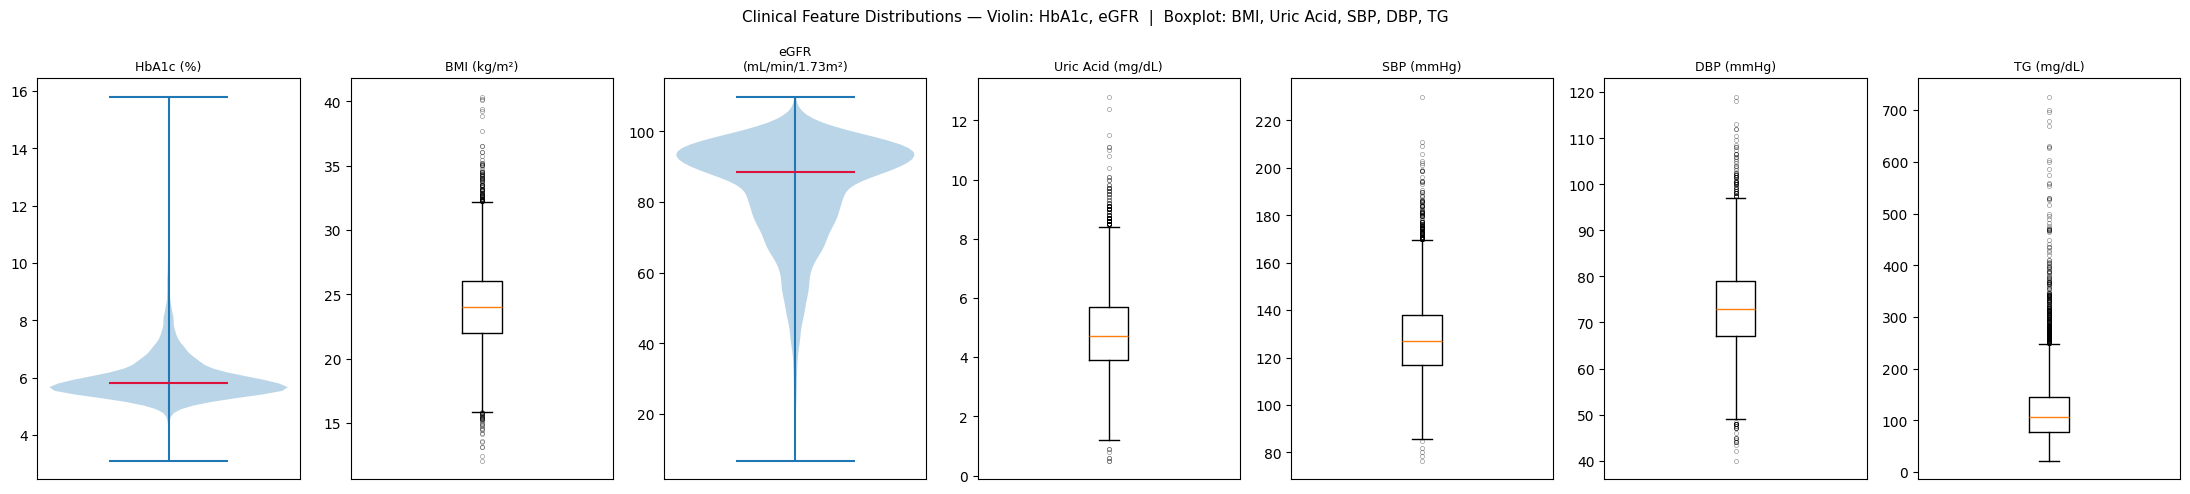

In [56]:
clinical_feats = ['HE_HbA1c', 'HE_BMI', 'eGFR', 'HE_Uacid', 'HE_sbp', 'HE_dbp', 'HE_TG']
feat_labels    = ['HbA1c (%)', 'BMI (kg/m\u00b2)', 'eGFR\n(mL/min/1.73m\u00b2)',
                   'Uric Acid (mg/dL)', 'SBP (mmHg)', 'DBP (mmHg)', 'TG (mg/dL)']
violin_feats   = {'HE_HbA1c', 'eGFR'}   # non-normal distributions — violin shows full shape

fig, axes = plt.subplots(1, 7, figsize=(22, 5))
for ax, col, label in zip(axes, clinical_feats, feat_labels):
    data = df_subset[col].dropna().values
    if col in violin_feats:
        parts = ax.violinplot(data, positions=[1], showmedians=True, showextrema=True)
        parts['cmedians'].set_color('crimson')
        parts['cmedians'].set_linewidth(1.5)
    else:
        ax.boxplot(data,
                   flierprops=dict(marker='o', markerfacecolor='none',
                                   markeredgewidth=0.5, markersize=3, alpha=0.4))
    ax.set_title(label, fontsize=9)
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    ax.set_ylabel('')

fig.suptitle(
    'Clinical Feature Distributions — Violin: HbA1c, eGFR  |  Boxplot: BMI, Uric Acid, SBP, DBP, TG',
    fontsize=11
)
plt.tight_layout()
plt.show()

In [57]:
# Combined diabetes: diagnosed (DE1_dg == 1) OR HbA1c ≥ 6.5%
# NaN comparisons return False, so OR logic is safe — only set NaN when both sources are missing
diagnosed = (df_subset['DE1_dg'] == 1)
hba1c_pos = (df_subset['HE_HbA1c'] >= 6.5)
df_subset['diabetes'] = (diagnosed | hba1c_pos).astype(float)

both_missing = df_subset['DE1_dg'].isna() & df_subset['HE_HbA1c'].isna()
df_subset.loc[both_missing, 'diabetes'] = np.nan
df_subset = df_subset.drop(columns=['DE1_dg'])

# Hypertension binary: SBP ≥ 140 OR DBP ≥ 90 (standard clinical threshold)
# NaN in either BP column → NaN result
sbp_pos = (df_subset['HE_sbp'] >= 140)
dbp_pos = (df_subset['HE_dbp'] >= 90)
df_subset['hypertension'] = (sbp_pos | dbp_pos).astype(float)

both_bp_missing = df_subset['HE_sbp'].isna() & df_subset['HE_dbp'].isna()
df_subset.loc[both_bp_missing, 'hypertension'] = np.nan


print(f"diabetes = 1 (combined): {int(df_subset['diabetes'].sum())}")
print(f"diabetes = 0:            {int((df_subset['diabetes'] == 0).sum())}")
print(f"diabetes = NaN:          {df_subset['diabetes'].isna().sum()}")
print(f"hypertension = 1:        {int(df_subset['hypertension'].sum())}")
print(f"hypertension = 0:        {int((df_subset['hypertension'] == 0).sum())}")
print(f"hypertension = NaN:      {df_subset['hypertension'].isna().sum()}")

diabetes = 1 (combined): 2166
diabetes = 0:            5537
diabetes = NaN:          1
hypertension = 1:        1722
hypertension = 0:        5893
hypertension = NaN:      89


<h4 style="color:lightblue;"> EDA — Diabetes &amp; Hypertension Prevalence </h4>

Both are derived binary flags (1 = condition present, 0 = absent). NaN rows (both source fields missing) are excluded from the bar counts. Percentages are of the valid (non-NaN) population.

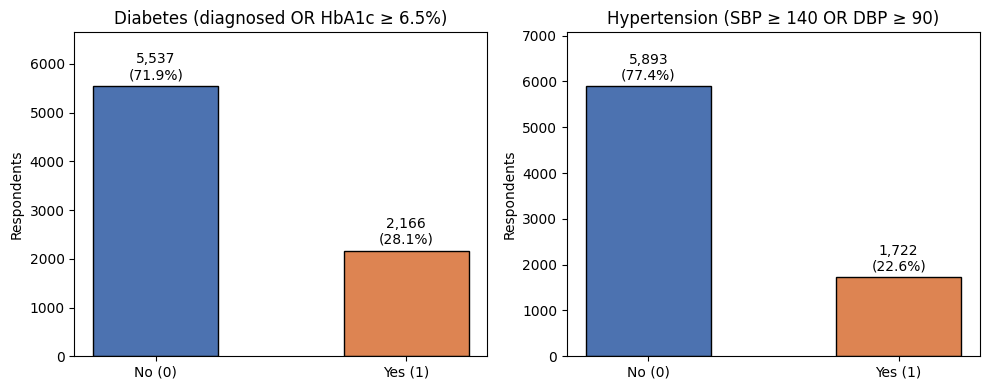

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col, title in zip(
    axes,
    ['diabetes', 'hypertension'],
    ['Diabetes (diagnosed OR HbA1c ≥ 6.5%)', 'Hypertension (SBP ≥ 140 OR DBP ≥ 90)']
):
    counts = df_subset[col].value_counts().sort_index()
    total  = counts.sum()
    bars   = ax.bar(['No (0)', 'Yes (1)'], counts.values,
                    color=['#4C72B0', '#DD8452'], edgecolor='black', width=0.5)
    for bar, n in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + total * 0.01,
                f'{n:,}\n({n/total*100:.1f}%)',
                ha='center', va='bottom', fontsize=10)
    ax.set_title(title)
    ax.set_ylabel('Respondents')
    ax.set_ylim(0, counts.max() * 1.2)

plt.tight_layout()
plt.show()

In [59]:
# BM1_1–BM1_8: binary flags for each brushing occasion → sum = brushing frequency count (0–8)
bm1_cols = ['BM1_1','BM1_2','BM1_3','BM1_4','BM1_5','BM1_6','BM1_7','BM1_8']
df_subset['brush_freq'] = df_subset[bm1_cols].sum(axis=1, min_count=1)
# Non-brushers (BM1_0 == 0) have all 8 slots coded N/A → NaN sum; their true frequency is 0.
df_subset.loc[df_subset['BM1_0'] == 0, 'brush_freq'] = 0
# Remaining brush_freq NaN = BM1_0 itself missing (median-imputed downstream)

# interdental dropped: BM2_1/BM2_3 are absent from the HN23 & HN24 files, so the feature
# is 100% missing for all of 2023 and the entire 2024 test year — degenerate, removed.

print(f"brush_freq  NaN: {df_subset['brush_freq'].isna().sum()}")
print(df_subset['brush_freq'].value_counts().sort_index())

brush_freq  NaN: 277
brush_freq
0.0     250
1.0     776
2.0    2778
3.0    2382
4.0     907
5.0     253
6.0      65
7.0       9
8.0       7
Name: count, dtype: int64


<h4 style="color:lightblue;"> EDA — Brushing Frequency </h4>

`brush_freq`: sum of BM1_1–BM1_8 occasion flags (0–8); 0 = did not brush yesterday (BM1_0 == 0), NaN = BM1_0 missing.

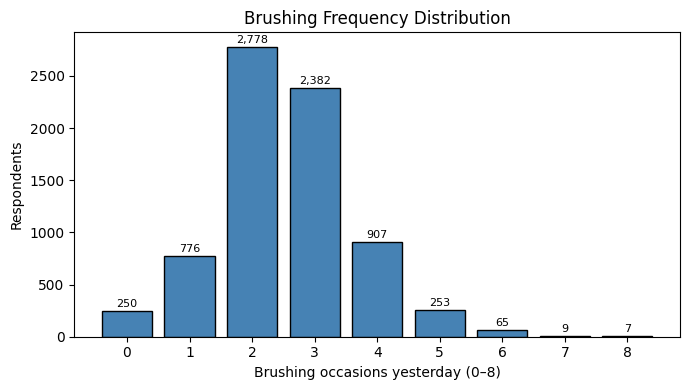

In [60]:
fig, ax = plt.subplots(figsize=(7, 4))

# ── brush_freq bar chart ──────────────────────────
bf        = df_subset['brush_freq'].dropna().astype(int)
counts_bf = bf.value_counts().sort_index()
ax.bar(counts_bf.index, counts_bf.values, color='steelblue', edgecolor='black')
ax.set_xlabel('Brushing occasions yesterday (0–8)')
ax.set_ylabel('Respondents')
ax.set_title('Brushing Frequency Distribution')
ax.set_xticks(range(9))
for x, y in zip(counts_bf.index, counts_bf.values):
    ax.text(x, y + len(bf) * 0.005, f'{y:,}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 4.4 EDA — Clinical Feature Distributions </h3>
Inspect the raw distributions of the key clinical exposures (HbA1c, eGFR, BMI)
before imputation and scaling. The dashed line marks the HbA1c ≥ 6.5% diabetes cutoff.

there is no cutoff for eGFR because the average value of eGFR is significantly based on a person's age, sex, and other factors

|                          | HbA1c                             | BMI                                 |
| ------------------------ | --------------------------------- | ----------------------------------- |
| Measures                 | Blood-sugar control               | Body fatness                        |
| Role                     | **Diagnostic** (defines diabetes) | **Risk factor** (predicts diabetes) |
| Cutoff for diabetes      | Yes — ≥ 6.5%                      | No                                  |
| Relationship to diabetes | _Is_ the disease state            | A _cause/correlate_ of it           |

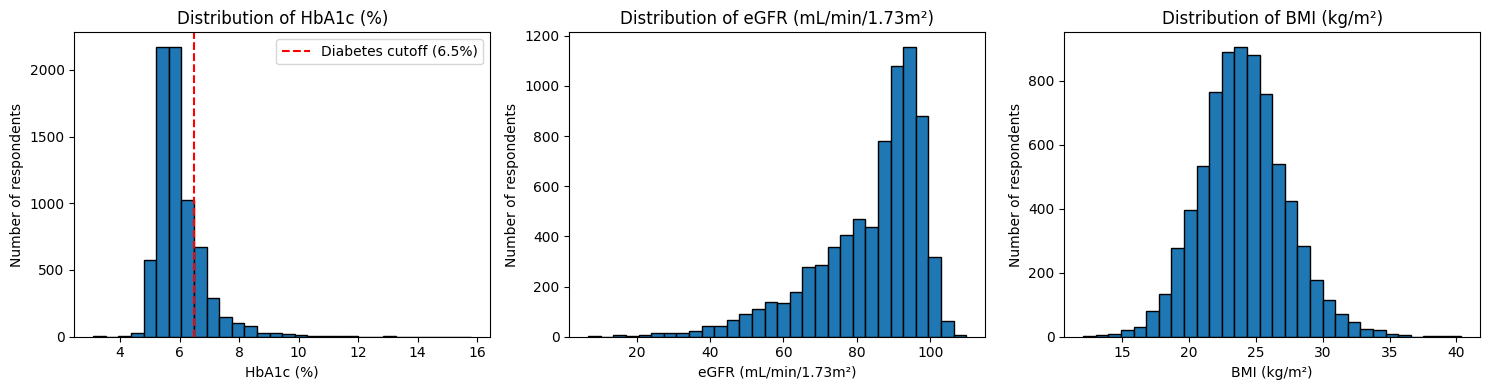

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cols   = ['HE_HbA1c', 'eGFR', 'HE_BMI']
labels = ['HbA1c (%)', 'eGFR (mL/min/1.73m²)', 'BMI (kg/m²)']

for ax, col, label in zip(axes, cols, labels):
    ax.hist(df_subset[col].dropna(), bins=30, edgecolor='black')
    ax.set_xlabel(label)
    ax.set_ylabel('Number of respondents')
    ax.set_title(f'Distribution of {label}')

# mark the diabetes threshold on the HbA1c plot (your diabetes = HbA1c ≥ 6.5%)
axes[0].axvline(6.5, color='red', linestyle='--', label='Diabetes cutoff (6.5%)')
axes[0].legend()

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 4.5 EDA — Tooth-Loss Rate by Subgroup </h3>

<h4 style="color:#7FDBFF";> How tooth loss was derived: </h4>
Because O_TC_ is binary (0 or 1), taking the average of it gives you the fraction that are 1. For example, among 5 people 3 people have diabetes. That would result in
O_TC_ values: [1, 0, 1, 1, 0]
sum of 1 = 3 
count = 5
therefore, mean = 3/5 = 60% ; the mean is the rate so 60% have tooth loss

This concept relates to each histogram of education, income quartile, and diabetes 

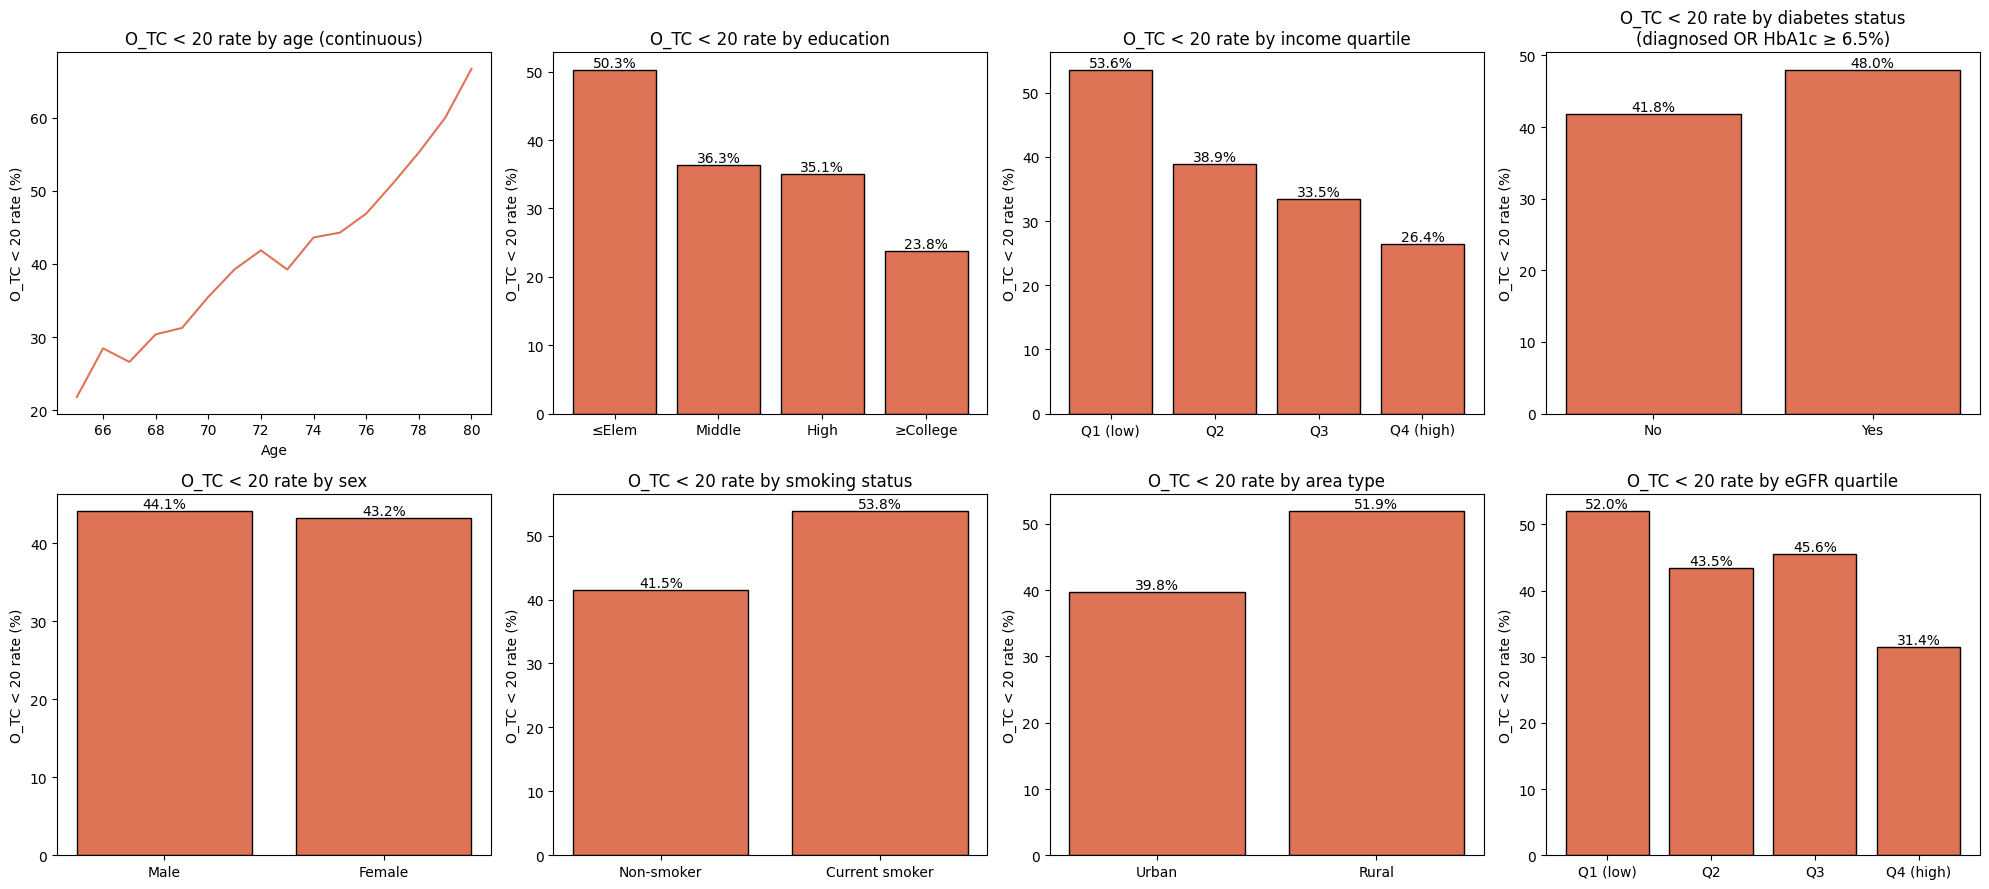

In [62]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

def plot_rate(ax, grouper, title, label_map):
    rate = df_subset["O_TC_"].groupby(grouper, observed=True).mean() * 100
    bars = ax.bar(range(len(rate)), rate.values, color= '#DE7356', edgecolor="black")
    ax.set_xticks(range(len(rate)))
    # labels follow the actual groupby order (groupby sorts its keys) so they can't desync
    ax.set_xticklabels([label_map.get(k, str(k)) for k in rate.index])
    ax.set_ylabel("O_TC < 20 rate (%)")
    ax.set_title(title)
    for bar, v in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom")

# 1. Age (continuous)
age_rate = df_subset.groupby("age")["O_TC_"].mean() * 100
axes[0, 0].plot(age_rate.index, age_rate.values, color= "#DE7356", linewidth=1.5)
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("O_TC < 20 rate (%)")
axes[0, 0].set_title("O_TC < 20 rate by age (continuous)")

# 2. Education
plot_rate(axes[0, 1], df_subset["edu"], "O_TC < 20 rate by education",
          {1: "≤Elem", 2: "Middle", 3: "High", 4: "≥College"})

# 3. Income quartile
plot_rate(axes[0, 2], df_subset["ho_incm"], "O_TC < 20 rate by income quartile",
          {1: "Q1 (low)", 2: "Q2", 3: "Q3", 4: "Q4 (high)"})

# 4. Diabetes
plot_rate(axes[0, 3], df_subset["diabetes"], "O_TC < 20 rate by diabetes status\n(diagnosed OR HbA1c ≥ 6.5%)",
          {0.0: "No", 1.0: "Yes"})

# 5. Sex
plot_rate(axes[1, 0], df_subset["sex"], "O_TC < 20 rate by sex",
          {1: "Male", 2: "Female"})

# 6. Smoking
plot_rate(axes[1, 1], df_subset["sm_presnt"], "O_TC < 20 rate by smoking status",
          {0: "Non-smoker", 1: "Current smoker"})

# 7. Urban vs. Rural
plot_rate(axes[1, 2], df_subset["town_t"], "O_TC < 20 rate by area type",
          {1: "Urban", 2: "Rural"})

# 8. eGFR quartile
egfr_q = pd.qcut(df_subset["eGFR"], q=4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
plot_rate(axes[1, 3], egfr_q, "O_TC < 20 rate by eGFR quartile",
          {c: c for c in ["Q1 (low)", "Q2", "Q3", "Q4 (high)"]})

plt.tight_layout()
plt.show()

<h2 style="color:#FFA500;"> 5. Train / Test Split (Temporal) & Median Imputation </h2>

Split by survey year to respect the temporal ordering of data collection:

| Set | Source files | Years |
|-----|-------------|-------|
| **Train** | HN20_all.csv, HN21_all.csv, HN22_all.csv, HN23_all.csv | 2020, 2021, 2022, 2023 |
| **Test** | HN24_all.csv | 2024 |

The imputer is fitted on the training fold only and applied to the test set without refitting, preventing data leakage. `year` is used solely as a split key and is excluded from `feature_cols`.

In [63]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# ML feature frame: work on a copy so df_subset stays intact for the inferential model
feat = df_subset.copy()

# B5: BD1 uses KNHANES 1=Yes/2=No -> recode to 1/0. O_pain and MO4_00 are already
# 0/1 in the data (verified in raw CSVs), so they are left as-is.
feat['BD1'] = feat['BD1'].map({1: 1, 2: 0})
# B8: reverse BP1 so higher = more stressed (matches the inferential coding)
feat['BP1'] = 5 - feat['BP1']
# BS12_1: 1=exposed, 2=not exposed -> recode to 1/0 (binary)
feat['BS12_1'] = feat['BS12_1'].map({1: 1, 2: 0})

# B6/B7: one-hot encode nominal vars (tins, region, occp, house, live_t); trees unaffected, fixes LR
# (nominal codes have no interval order — raw scaled integers would mislead the LR model)
feat = pd.get_dummies(feat, columns=['tins', 'region', 'occp', 'house', 'live_t'],
                      prefix=['tins', 'region', 'occp', 'house', 'live_t'],
                      dummy_na=False, dtype=float)
tins_dummies   = sorted([c for c in feat.columns if c.startswith('tins_')])
region_dummies = sorted([c for c in feat.columns if c.startswith('region_')])
occp_dummies   = sorted([c for c in feat.columns if c.startswith('occp_')])
house_dummies  = sorted([c for c in feat.columns if c.startswith('house_')])
live_t_dummies = sorted([c for c in feat.columns if c.startswith('live_t_')])
nominal_dummies = tins_dummies + region_dummies + occp_dummies + house_dummies + live_t_dummies

ordinal_cols = [
    # SES / demographics  (tins, region, occp, house, live_t are one-hot, appended below)
    'sex', 'ho_incm', 'edu', 'marri_1', 'cfam', 'town_t',
    # lifestyle / behavior
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1', 'L_BR_FQ', 'BS12_1',
    # urinalysis ordinal
    'HE_Upro',
    # dental
    'O_pain',
    'MO4_00', 'BM1_0',
    # derived
    'diabetes',
    # interdental dropped: BM2_1/BM2_3 absent from 2023-2024 files (100% missing on test year)
    # hypertension dropped (C-parallel): redundant with raw HE_sbp/HE_dbp, which are kept
] + nominal_dummies
continuous_cols = [
    # demographics
    'age',
    # original lab
    'HE_BMI', 'eGFR',
    # additional lab
    'HE_Uacid', 'HE_TG', 'HE_sbp', 'HE_dbp',
    # urinalysis continuous
    'HE_Ucrea',
    # dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR',
    # dental composite
    'brush_freq',
]
feature_cols = ordinal_cols + continuous_cols


# Temporal split: train on 2020-2023, test on 2024 (masks from df_subset; feat shares its index)
train_mask = df_subset['year'].isin([2020.0, 2021.0, 2022.0, 2023.0])
test_mask  = df_subset['year'].isin([2024.0])

X_train = feat.loc[train_mask, feature_cols].replace([np.inf, -np.inf], np.nan)
X_test  = feat.loc[test_mask,  feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = df_subset.loc[train_mask, 'O_TC_']
y_test  = df_subset.loc[test_mask,  'O_TC_']

print(f"Train size: {len(X_train)} | years: {sorted(df_subset.loc[train_mask, 'year'].unique())}")
print(f"Test  size: {len(X_test)}  | years: {sorted(df_subset.loc[test_mask,  'year'].unique())}")
print(f"Ordinal NaNs (train):    {X_train[ordinal_cols].isna().sum().sum()}")
print(f"Continuous NaNs (train): {X_train[continuous_cols].isna().sum().sum()}")
print(f"Total NaNs (train):      {X_train.isna().sum().sum()}")

def make_imputer():
    return ColumnTransformer([
        ('mode',   SimpleImputer(strategy='most_frequent'), ordinal_cols),
        ('median', SimpleImputer(strategy='median'),        continuous_cols),
    ])

Train size: 5946 | years: [np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0)]
Test  size: 1758  | years: [np.float64(2024.0)]
Ordinal NaNs (train):    3020
Continuous NaNs (train): 5309
Total NaNs (train):      8329


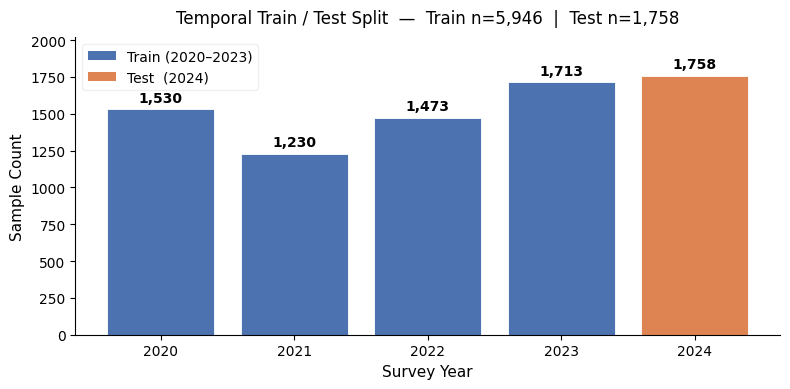

In [64]:
# ── Train / Test split — sample count by year ─────────────────────────────────────────────
year_counts = df_subset["year"].value_counts().sort_index()

colors = ["#4C72B0" if y != 2024.0 else "#DD8452" for y in year_counts.index]
labels = [str(int(y)) for y in year_counts.index]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(labels, year_counts.values, color=colors, edgecolor="white", linewidth=0.6)

for bar, val in zip(bars, year_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 30,
            f"{val:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", label="Train (2020–2023)"),
    Patch(facecolor="#DD8452", label="Test  (2024)"),
]
ax.legend(handles=legend_elements, fontsize=10, framealpha=0.3)

train_n = year_counts[year_counts.index != 2024.0].sum()
test_n  = year_counts.get(2024.0, 0)
ax.set_title(
    f"Temporal Train / Test Split  —  Train n={train_n:,}  |  Test n={test_n:,}",
    fontsize=12, pad=10
)
ax.set_xlabel("Survey Year", fontsize=11)
ax.set_ylabel("Sample Count", fontsize=11)
ax.set_ylim(0, year_counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

<h2 style="color:#FFA500";> 6. Model Training </h2>

Five classifiers are tuned with Optuna (50 trials, 5-fold stratified CV, AUPRC objective). XGBoost tunes `scale_pos_weight` to address class imbalance; the remaining models rely on their native class-handling.

In [65]:
from sklearn.pipeline import Pipeline

print("Class distribution:")
print(pd.Series(y_train).value_counts().to_dict())
print(f"Positive rate: {y_train.mean():.3f}")


Class distribution:
{0: 3313, 1: 2633}
Positive rate: 0.443


<h2 style="color:#FFA500";> 7. Hyperparameter Tuning — Optuna </h2>

**Method:** Single **50-trial Optuna TPE pass** per model using 5-fold `StratifiedKFold`, scored by `average_precision`. XGBoost additionally tunes `scale_pos_weight` to handle class imbalance; other models rely on native imbalance handling.

**Standardization policy:** `StandardScaler` is added to the Logistic Regression pipeline only — tree-based models are scale-invariant by construction.

| Model | Key hyperparameters tuned |
|-------|--------------------------|
| **Random Forest** | `n_estimators`, `max_depth`*, `min_samples_leaf`* |
| **XGBoost** | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`, `reg_lambda`*, `scale_pos_weight` |
| **LightGBM** | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples`, `reg_lambda`* |
| **CatBoost** | `iterations`, `depth`, `learning_rate`, `l2_leaf_reg`* |
| **Logistic Regression** | `C`* (inverse strength), `l1_ratio` (ElasticNet mix, SAGA solver) |

\* = regularization parameter

**Method:** Optuna TPE search (sample-efficient — learns from past trials, unlike random search; 50 trials per model, `scoring = 'average_precision'`)

| Model                   | Key Hyperparameters                                                                                                              | Search Range                                                                                                       |
| :---------------------- | :------------------------------------------------------------------------------------------------------------------------------- | :----------------------------------------------------------------------------------------------------------------- |
| **Random Forest**       | `n_estimators`, `max_depth`, `min_samples_leaf`                                                                                  | 100–500 (step 100) · {5,10,15,None} · 1–10                                                                        |
| **XGBoost**             | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`, `reg_lambda`, `scale_pos_weight` | 100–700 · 3–7 · 0.01–0.3 (log) · 0.7–1.0 · 0.5–1.0 · 1–6 · 0–5 · 0.01–10 (log) · {1.5, 2.0, 2.7, 3.5, 5.0} |
| **LightGBM**            | `n_estimators`, `num_leaves`, `learning_rate`, `min_child_samples`, `reg_lambda`                                                 | 100–500 · 15–63 · 0.01–0.3 (log) · 5–20 · 0.01–10 (log)                                                          |
| **CatBoost**            | `iterations`, `depth`, `learning_rate`, `l2_leaf_reg`                                                                           | 100–500 · 3–8 · 0.01–0.3 (log) · 1–10                                                                             |
| **Logistic Regression** | `C`, `l1_ratio` (ElasticNet via SAGA)                                                                                           | 0.001–100 (log) · 0.0–1.0                                                                                         |

<h3 style="color:yellow";> 7.1 Objective Function Definitions </h3>

Define one Optuna objective per model. Each objective runs 5-fold `StratifiedKFold` CV and returns the mean `average_precision`. The imputer is rebuilt inside every CV fold to prevent data leakage.

**Regularization parameters per model:**

| Model | Regularization parameter(s) | Type | Search range |
|---|---|---|---|
| Random Forest | `max_depth`, `min_samples_leaf` | Structural (limits tree size) | depth ∈ {5,10,15,None} · leaf ∈ [1,10] |
| XGBoost | `reg_lambda` | L2 weight penalty | [0.01, 10] log-scale |
| LightGBM | `reg_lambda` | L2 weight penalty | [0.01, 10] log-scale |
| CatBoost | `l2_leaf_reg` | L2 leaf penalty | [1, 10] |
| Logistic Regression | `C`, `l1_ratio` | Inverse ElasticNet strength; L1/L2 mix ratio | C ∈ [0.001, 100] log-scale · l1_ratio ∈ [0, 1] |

In [66]:
import optuna
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

cv       = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
N_TRIALS = 50

def cv_score(estimator):
    return cross_val_score(estimator, X_train, y_train,
                           cv=cv, scoring='average_precision', n_jobs=1).mean()   # n_jobs=1: avoid macOS fork-kill under memory pressure

def obj_rf(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', RandomForestClassifier(
            n_estimators     = trial.suggest_int('n_estimators', 100, 500, step=100),
            max_depth        = trial.suggest_categorical('max_depth', [5, 10, 15, None]),
            min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10),
            class_weight='balanced', random_state=42, n_jobs=-1))
    ])
    return cv_score(model)

def obj_xgb(trial):
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 100, 700, step=100),
        max_depth         = trial.suggest_int('max_depth', 3, 7),
        learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        subsample         = trial.suggest_float('subsample', 0.7, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight  = trial.suggest_int('min_child_weight', 1, 6),
        gamma             = trial.suggest_float('gamma', 0.0, 5.0),
        reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
        scale_pos_weight  = trial.suggest_categorical('scale_pos_weight', [1.0, 1.29, 1.5, 2.0, 2.5]),
        eval_metric='logloss', random_state=42, nthread=1)
    scores = []
    for tr_idx, val_idx in cv.split(X_train, y_train):
        Xtr,  Xval  = X_train.iloc[tr_idx],  X_train.iloc[val_idx]
        ytr,  yval  = y_train.iloc[tr_idx],  y_train.iloc[val_idx]
        imp      = make_imputer()
        Xtr_imp  = imp.fit_transform(Xtr)
        Xval_imp = imp.transform(Xval)
        model = XGBClassifier(**params)
        model.fit(Xtr_imp, ytr)
        scores.append(average_precision_score(yval, model.predict_proba(Xval_imp)[:, 1]))
    return np.mean(scores)

def obj_lgbm(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', LGBMClassifier(
            n_estimators      = trial.suggest_int('n_estimators', 100, 500, step=100),
            num_leaves        = trial.suggest_int('num_leaves', 15, 63),
            learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            min_child_samples = trial.suggest_int('min_child_samples', 5, 20),
            reg_lambda        = trial.suggest_float('reg_lambda', 1e-2, 10.0, log=True),
            class_weight='balanced', verbose=-1, random_state=42, n_jobs=1))
    ])
    return cv_score(model)

def obj_cat(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('model', CatBoostClassifier(
            iterations    = trial.suggest_int('iterations', 100, 500, step=100),
            depth         = trial.suggest_int('depth', 3, 8),
            learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            l2_leaf_reg   = trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
            auto_class_weights='Balanced', random_seed=42, verbose=0))
    ])
    return cv_score(model)

def obj_lr(trial):
    model = Pipeline([
        ('imputer', make_imputer()),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            C            = trial.suggest_float('C', 1e-3, 1e2, log=True),
            penalty      = 'elasticnet',
            l1_ratio     = trial.suggest_float('l1_ratio', 0.0, 1.0),
            solver='saga', class_weight='balanced', max_iter=1000, random_state=42))
    ])
    return cv_score(model)

objectives = {
    'Random Forest':       obj_rf,
    'XGBoost':             obj_xgb,
    'LightGBM':            obj_lgbm,
    'CatBoost':            obj_cat,
    'Logistic Regression': obj_lr,
}

<h3 style="color:yellow";> 7.2 Tuning — 50-Trial Optuna Pass </h3>

50-trial Optuna TPE study per model using 5-fold CV and the search spaces defined in §7.1. Best params and best CV AUPRC are stored in `results` for the refit and test-set evaluation in §8.

In [67]:
results = {}
for name, objective in objectives.items():
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    results[name] = {
        'best_params':   study.best_params,
        'best_cv_score': study.best_value,
        'study':         study
    }
    print(f"{name}: Best AUPRC = {study.best_value:.4f} | Params: {study.best_params}")

results_df = pd.DataFrame(
    {name: {'AUPRC': v['best_cv_score']} for name, v in results.items()}
).T.sort_values('AUPRC', ascending=False)
print(results_df)

Random Forest: Best AUPRC = 0.6660 | Params: {'n_estimators': 400, 'max_depth': 10, 'min_samples_leaf': 7}
XGBoost: Best AUPRC = 0.6704 | Params: {'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.04335819505576406, 'subsample': 0.7701559324287586, 'colsample_bytree': 0.5391720618855236, 'min_child_weight': 6, 'gamma': 3.285627753863364, 'reg_lambda': 5.689348119466204, 'scale_pos_weight': 2.0}
LightGBM: Best AUPRC = 0.6628 | Params: {'n_estimators': 400, 'num_leaves': 20, 'learning_rate': 0.011915926881650859, 'min_child_samples': 17, 'reg_lambda': 8.675050252832106}
CatBoost: Best AUPRC = 0.6741 | Params: {'iterations': 500, 'depth': 4, 'learning_rate': 0.02320343322275369, 'l2_leaf_reg': 3.5775589146515063}


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:349: ConvergenceWarning: The ma

Logistic Regression: Best AUPRC = 0.6768 | Params: {'C': 0.05472265404590902, 'l1_ratio': 0.4228738347125746}
                        AUPRC
Logistic Regression  0.676774
CatBoost             0.674139
XGBoost              0.670418
Random Forest        0.666015
LightGBM             0.662822


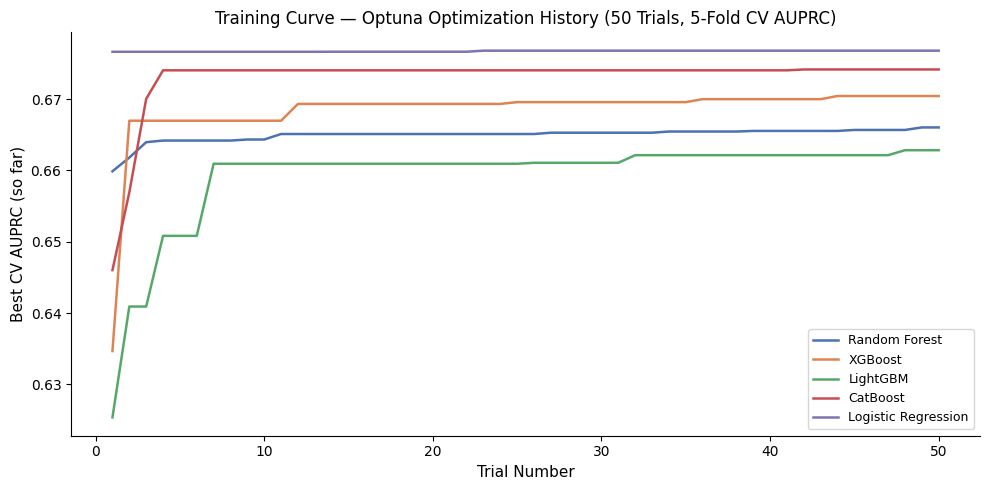

In [68]:
# ── Training Curve — Optuna Optimization History ────────────────────────────────
# Running best CV AUPRC over 50 TPE trials per model.
# Plateau early → converged; still rising at trial 50 → more budget may help.

_opt_colors = {
    'Random Forest':       '#4C72B0',
    'XGBoost':             '#DD8452',
    'LightGBM':            '#55A868',
    'CatBoost':            '#C44E52',
    'Logistic Regression': '#8172B2',
}

fig, ax = plt.subplots(figsize=(10, 5))
for name, info in results.items():
    trial_vals  = [t.value for t in info['study'].trials if t.value is not None]
    best_so_far = np.maximum.accumulate(trial_vals)
    ax.plot(range(1, len(best_so_far) + 1), best_so_far,
            linewidth=1.8, label=name, color=_opt_colors.get(name))

ax.set_xlabel('Trial Number', fontsize=11)
ax.set_ylabel('Best CV AUPRC (so far)', fontsize=11)
ax.set_title('Training Curve — Optuna Optimization History (50 Trials, 5-Fold CV AUPRC)', fontsize=12)
ax.legend(loc='lower right', fontsize=9)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

<h2 style="color:#FFA500";> 8. Refit & Evaluate Tuned Models on the Test Set </h2>

Rebuild each model from its Optuna-best params, fit on the 2020–2023 training fold, and score on the held-out 2024 test set. This compares cross-validated AUPRC (Optuna objective) against out-of-sample test AUC and AUPRC, selecting the best model by Test AUPRC for the diagnostics in §9.

> Replaces the earlier PyCaret `compare_models` screening — Optuna already tunes the chosen models directly, so a separate AutoML pass is redundant.

**Note — predictive metrics are unweighted.** The AUC / AUPRC / confusion matrices below are computed on the raw sample, *not* survey-weighted. KNHANES sampling weights are applied only in the inferential (odds-ratio) model. Rank metrics (AUC/AUPRC) are largely insensitive to weighting, but all reported predictive performance describes the **sample**, not the Korean population.

In [69]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict

def build_estimator(name, params):
    if name == "Random Forest":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", RandomForestClassifier(
                class_weight="balanced", random_state=42, n_jobs=-1, **params))
        ])
    if name == "XGBoost":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", XGBClassifier(
                eval_metric="logloss", random_state=42, nthread=1, **params))
        ])
    if name == "LightGBM":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", LGBMClassifier(
                class_weight="balanced", verbose=-1, random_state=42, n_jobs=1, **params))
        ])
    if name == "CatBoost":
        return Pipeline([
            ("imputer", make_imputer()),
            ("model", CatBoostClassifier(
                auto_class_weights="Balanced", random_seed=42, verbose=0, **params))
        ])
    if name == "Logistic Regression":
        return Pipeline([
            ("imputer", make_imputer()),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                penalty="elasticnet", class_weight="balanced",
                solver="saga", max_iter=1000, random_state=42, **params))
        ])
    raise ValueError(name)

fitted_models = {}
rows = []
for name, info in results.items():
    est = build_estimator(name, info["best_params"])
    oof_proba  = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    oof_auprc  = average_precision_score(y_train, oof_proba)
    est.fit(X_train, y_train)
    fitted_models[name] = est
    proba = est.predict_proba(X_test)[:, 1]
    test_auc   = roc_auc_score(y_test, proba)
    test_auprc = average_precision_score(y_test, proba)
    rows.append({"Model": name,
                 "CV AUPRC":     info["best_cv_score"],
                 "OOF AUPRC":  oof_auprc,
                 "Test AUC":   test_auc,
                 "Test AUPRC": test_auprc})

# Rank by Test AUPRC (per professor instruction: use test set for final model selection)
eval_df = (pd.DataFrame(rows)
             .set_index("Model")
             .sort_values("Test AUPRC", ascending=False))
print(eval_df.round(4).to_string())

best_name  = eval_df.index[0]  # selected by Test AUPRC (prioritises minority-class detection)
best_model = fitted_models[best_name]
print(f'Best model by Test AUPRC: {best_name} (Test AUPRC = {eval_df.loc[best_name, "Test AUPRC"]:.4f}) | Test AUC: {eval_df.loc[best_name, "Test AUC"]:.4f} | CV AUPRC: {eval_df.loc[best_name, "CV AUPRC"]:.4f}')

                     CV AUPRC  OOF AUPRC  Test AUC  Test AUPRC
Model                                                         
LightGBM               0.6628     0.6607    0.7194      0.6798
CatBoost               0.6741     0.6720    0.7222      0.6758
Logistic Regression    0.6768     0.6739    0.7203      0.6753
XGBoost                0.6704     0.6682    0.7213      0.6742
Random Forest          0.6660     0.6635    0.7190      0.6696
Best model by Test AUPRC: LightGBM (Test AUPRC = 0.6798) | Test AUC: 0.7194 | CV AUPRC: 0.6628


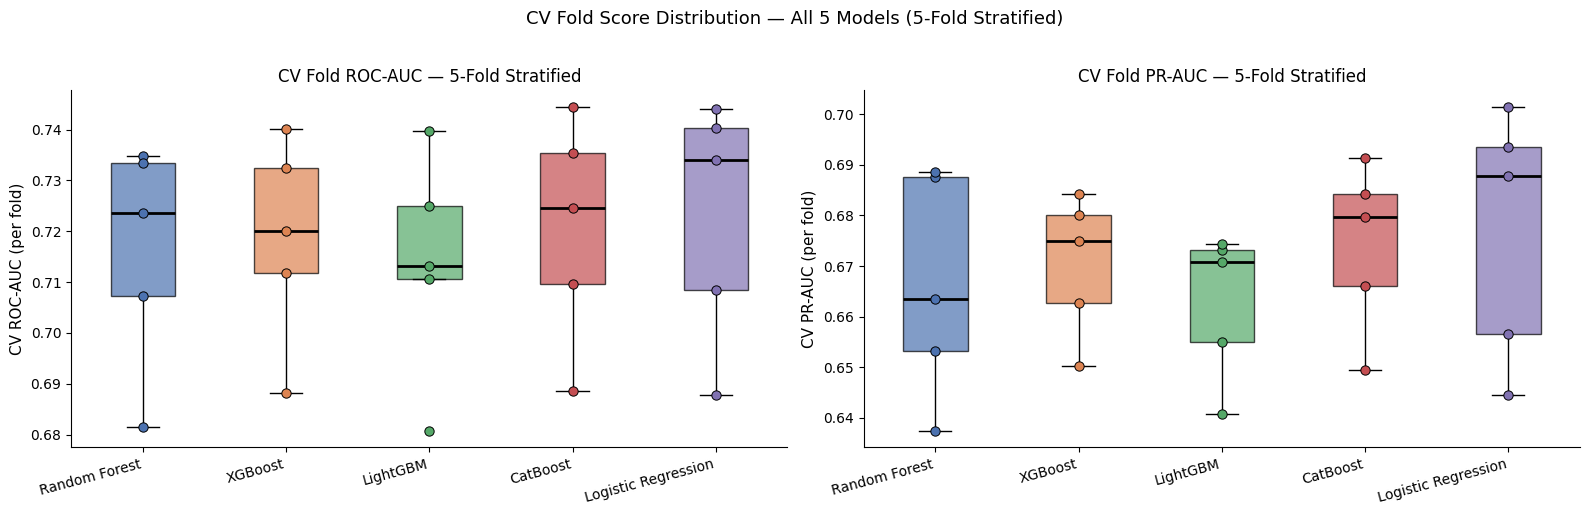

In [70]:
from sklearn.model_selection import cross_val_score

# ── CV Fold AUC / PR-AUC Distribution — All 5 Models (5-Fold Stratified) ────
# Boxplot chosen over violin: only 5 data points per model — KDE needs more.
# Individual fold scores overlaid as scatter to show spread transparently.
# PR-AUC (average_precision) added alongside ROC-AUC: dataset is imbalanced
# (scale_pos_weight=2 in XGBoost), so ROC-AUC alone overstates performance.

_cv_palette = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]

_fold_scores_roc = {}
_fold_scores_pr  = {}
for _name, _info in results.items():
    _est = build_estimator(_name, _info["best_params"])
    _fold_scores_roc[_name] = cross_val_score(
        _est, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1
    )
    _fold_scores_pr[_name] = cross_val_score(
        _est, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=1
    )

_cv_names = list(_fold_scores_roc.keys())

def _draw_cv_boxplot(ax, scores_dict, names, palette, ylabel, title):
    data = [scores_dict[n] for n in names]
    bp = ax.boxplot(data, patch_artist=True, widths=0.45,
                    medianprops=dict(color="black", linewidth=2),
                    flierprops=dict(marker="o", markersize=5, alpha=0.5))
    for patch, color in zip(bp["boxes"], palette):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    for i, (scores, color) in enumerate(zip(data, palette), start=1):
        ax.scatter([i] * len(scores), scores,
                   color=color, zorder=3, s=45, edgecolors="black", linewidths=0.7)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, fontsize=10, rotation=15, ha="right")
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

_draw_cv_boxplot(
    ax1, _fold_scores_roc, _cv_names, _cv_palette,
    ylabel="CV ROC-AUC (per fold)",
    title="CV Fold ROC-AUC — 5-Fold Stratified",
)
_draw_cv_boxplot(
    ax2, _fold_scores_pr, _cv_names, _cv_palette,
    ylabel="CV PR-AUC (per fold)",
    title="CV Fold PR-AUC — 5-Fold Stratified",
)

fig.suptitle("CV Fold Score Distribution — All 5 Models (5-Fold Stratified)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [71]:
for name, info in results.items():
    print(f"\n── {name} ──")
    for param, val in info['best_params'].items():
        print(f"  {param:<22} {val}")


── Random Forest ──
  n_estimators           400
  max_depth              10
  min_samples_leaf       7

── XGBoost ──
  n_estimators           200
  max_depth              3
  learning_rate          0.04335819505576406
  subsample              0.7701559324287586
  colsample_bytree       0.5391720618855236
  min_child_weight       6
  gamma                  3.285627753863364
  reg_lambda             5.689348119466204
  scale_pos_weight       2.0

── LightGBM ──
  n_estimators           400
  num_leaves             20
  learning_rate          0.011915926881650859
  min_child_samples      17
  reg_lambda             8.675050252832106

── CatBoost ──
  iterations             500
  depth                  4
  learning_rate          0.02320343322275369
  l2_leaf_reg            3.5775589146515063

── Logistic Regression ──
  C                      0.05472265404590902
  l1_ratio               0.4228738347125746


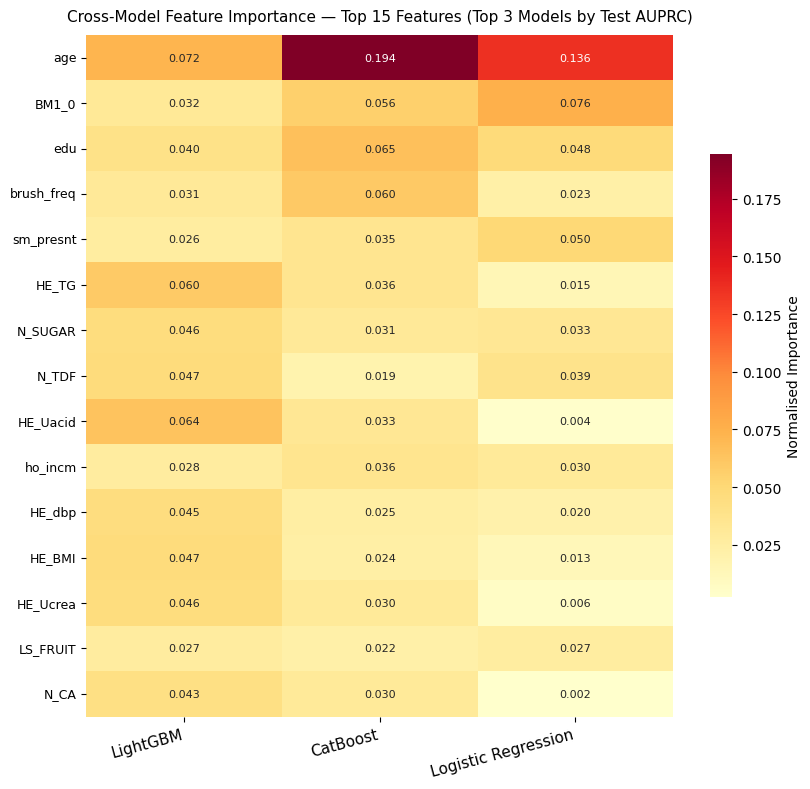

In [72]:
import seaborn as sns

# ── Cross-Model Feature Importance Heatmap — Top 3 Models ───────────────────
# Compares normalised feature importances for the 3 best models (by Test AUPRC).
# Top 15 features by mean importance shown; each column sums to 1.

top3_names = eval_df.index[:3].tolist()

raw_imps = {}
for name in top3_names:
    step = fitted_models[name].named_steps['model']
    if hasattr(step, 'feature_importances_'):
        imp = step.feature_importances_.copy().astype(float)
    else:                                           # Logistic Regression
        imp = np.abs(step.coef_[0]).astype(float)
    imp /= imp.sum()
    raw_imps[name] = imp

imp_df  = pd.DataFrame(raw_imps, index=feature_cols)
top15   = imp_df.mean(axis=1).nlargest(15).index
plot_df = imp_df.loc[top15]

fig, ax = plt.subplots(figsize=(max(7, len(top3_names) * 2.8), 8))
sns.heatmap(plot_df, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax,
            annot_kws={'size': 8},
            cbar_kws={'label': 'Normalised Importance', 'shrink': 0.65})
ax.set_title(
    'Cross-Model Feature Importance — Top 15 Features (Top 3 Models by Test AUPRC)',
    fontsize=11, pad=10
)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=11, rotation=15, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9, rotation=0)
plt.tight_layout()
plt.show()

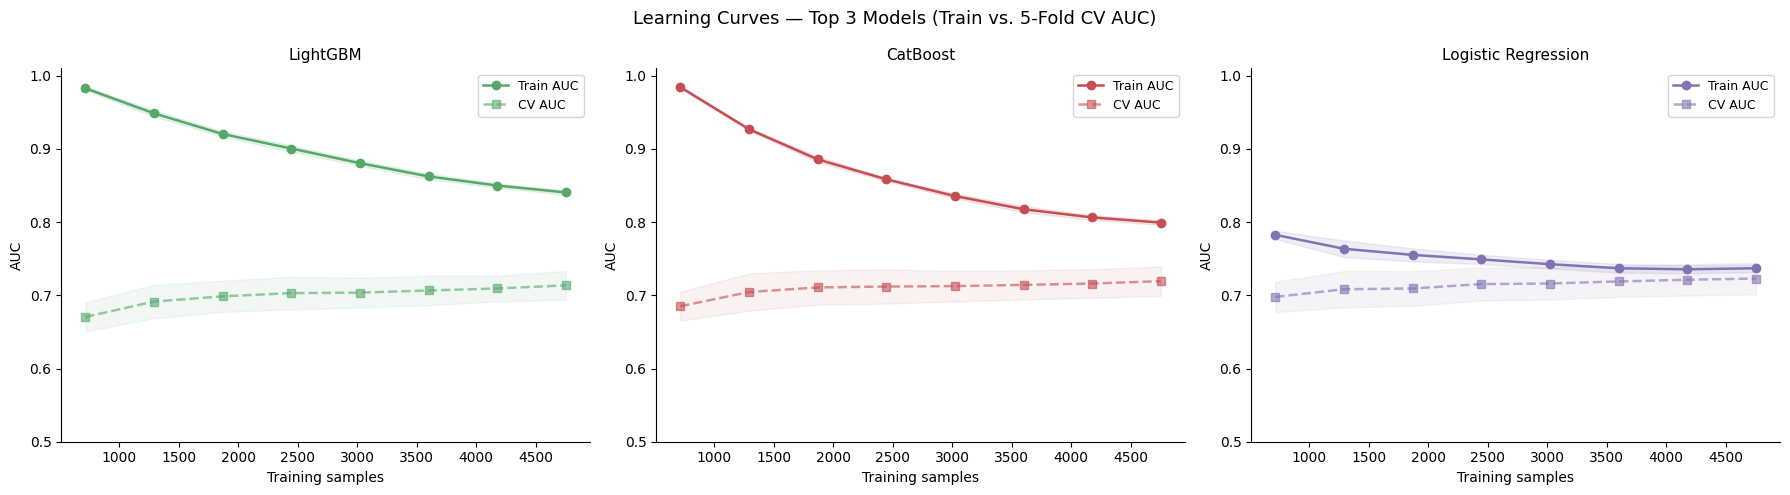

In [73]:
from sklearn.model_selection import learning_curve

# ── Learning Curve — Top 3 Models by Test AUPRC ─────────────────────────────
# Train AUC vs CV AUC across increasing training-set sizes.
# Converging gap → good generalisation; persistent gap → overfitting.

top3_names  = eval_df.index[:3].tolist()
train_sizes = np.linspace(0.15, 1.0, 8)

_lc_colors = {
    'Random Forest':       '#4C72B0',
    'XGBoost':             '#DD8452',
    'LightGBM':            '#55A868',
    'CatBoost':            '#C44E52',
    'Logistic Regression': '#8172B2',
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, top3_names):
    est = build_estimator(name, results[name]['best_params'])
    tr_sz, tr_scores, val_scores = learning_curve(
        est, X_train, y_train,
        train_sizes=train_sizes,
        cv=cv, scoring='roc_auc', n_jobs=1
    )
    tr_mean,  tr_std  = tr_scores.mean(axis=1),  tr_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)
    c = _lc_colors.get(name, '#333333')
    ax.plot(tr_sz, tr_mean, 'o-',  color=c, linewidth=1.8, label='Train AUC')
    ax.fill_between(tr_sz, tr_mean - tr_std,  tr_mean + tr_std,  alpha=0.12, color=c)
    ax.plot(tr_sz, val_mean, 's--', color=c, linewidth=1.8, alpha=0.6, label='CV AUC')
    ax.fill_between(tr_sz, val_mean - val_std, val_mean + val_std, alpha=0.08, color=c)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Training samples', fontsize=10)
    ax.set_ylabel('AUC', fontsize=10)
    ax.legend(fontsize=9)
    ax.set_ylim(0.5, 1.01)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Learning Curves — Top 3 Models (Train vs. 5-Fold CV AUC)', fontsize=13)
plt.tight_layout()
plt.show()

In [74]:
import shap

# ── Compute SHAP values for the best tuned model ────────────────────────
# X_test_imp: imputed (unscaled) test matrix in feature_cols order
X_test_imp = best_model.named_steps['imputer'].transform(X_test)

best_clf = best_model.named_steps['model']

if best_name == 'Logistic Regression':
    X_test_scaled = best_model.named_steps['scaler'].transform(X_test_imp)
    explainer   = shap.LinearExplainer(best_clf, X_test_scaled)
    shap_values = explainer.shap_values(X_test_scaled)
else:
    explainer = shap.TreeExplainer(best_clf)
    sv_raw    = explainer.shap_values(X_test_imp)
    shap_values = sv_raw[1] if isinstance(sv_raw, list) else sv_raw

print(f'Best model: {best_name}')
print(f'shap_values shape: {shap_values.shape}')
print(f'X_test_imp shape:  {X_test_imp.shape}')


Best model: LightGBM
shap_values shape: (1758, 67)
X_test_imp shape:  (1758, 67)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


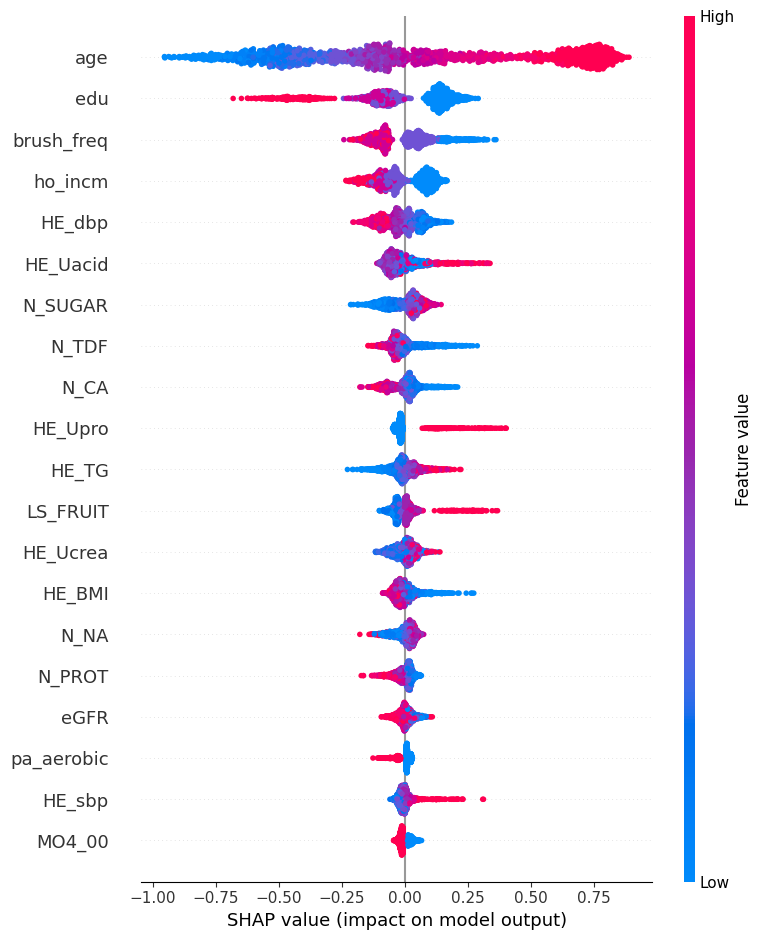

In [75]:

# Binary / low-cardinality categoricals are excluded — colour gradient is meaningless for them.
# They are plotted individually in the cell bel
# ow.
_excl = ({"sm_presnt", "diabetes", "O_pain", "BM1_0", "town_t"}
         | set(tins_dummies) | set(region_dummies)
         | set(occp_dummies) | set(house_dummies) | set(live_t_dummies))
_keep_idx   = [i for i, fc in enumerate(feature_cols) if fc not in _excl]
_keep_names = [fc for fc in feature_cols if fc not in _excl]

shap.summary_plot(
    shap_values[:, _keep_idx],
    X_test_imp[:, _keep_idx],
    feature_names=_keep_names
)

/var/folders/xt/mzqh8hz12q76z91q0t6kvzqm0000gn/T/ipykernel_6674/2646244907.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_, x="cat", y="SHAP", inner="box",
/var/folders/xt/mzqh8hz12q76z91q0t6kvzqm0000gn/T/ipykernel_6674/2646244907.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label_map.get(c, str(c)) for c in cats], fontsize=9)
/var/folders/xt/mzqh8hz12q76z91q0t6kvzqm0000gn/T/ipykernel_6674/2646244907.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_, x="cat", y="SHAP", inner="box",
/var/folders/xt/mzqh8hz12q76z91q0t6kvzqm0000gn/T/ipykernel_6674/264

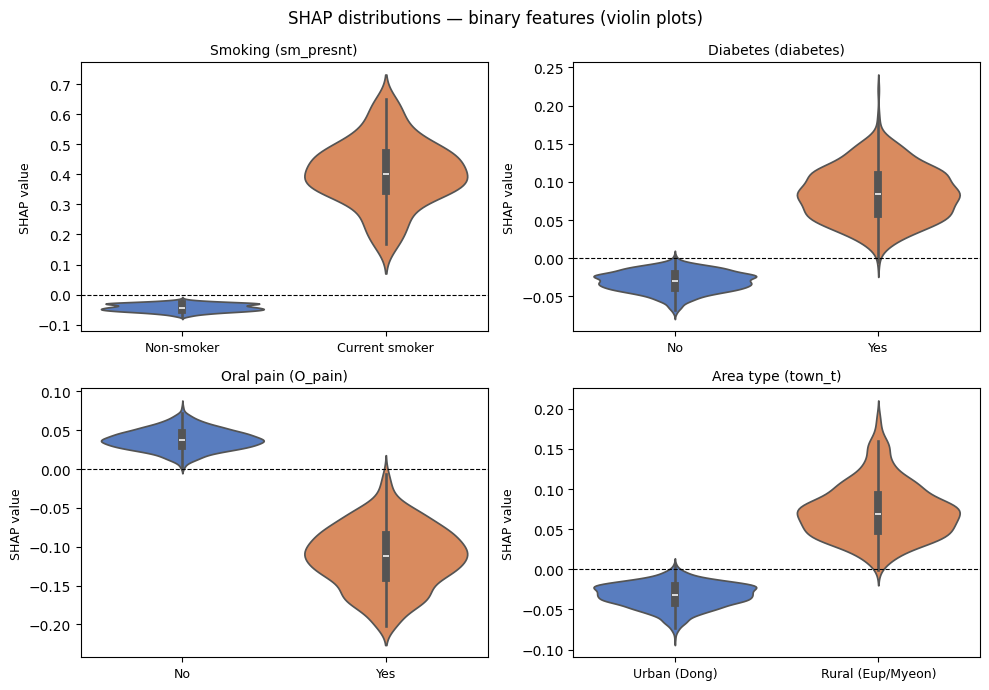

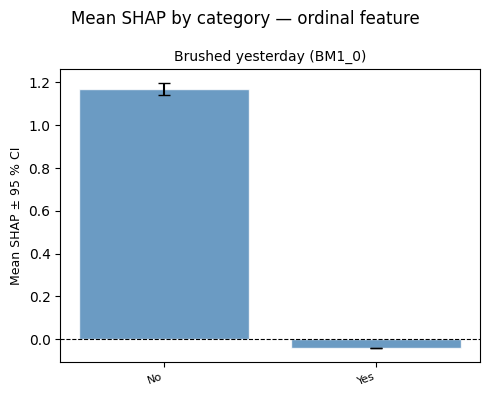

In [76]:
import seaborn as sns
from scipy import stats

# ── helpers ─────────────────────────────────────────────────────────────────
def _sv_fv(feat):
    idx = feature_cols.index(feat)
    sv  = shap_values[:, idx]
    fv  = X_test_imp[:, idx]
    mask = ~np.isnan(fv) & ~np.isnan(sv)
    return sv[mask], fv[mask]

def violin_panel(ax, feat, title, label_map):
    sv, fv = _sv_fv(feat)
    cats = sorted(np.unique(fv).astype(int))
    df_  = pd.DataFrame({"cat": fv.astype(int), "SHAP": sv})
    sns.violinplot(data=df_, x="cat", y="SHAP", inner="box",
                   order=cats, palette="muted", ax=ax)
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xticklabels([label_map.get(c, str(c)) for c in cats], fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("SHAP value", fontsize=9)
    ax.set_title(title, fontsize=10)

def bar_panel(ax, feat, title, label_map):
    sv, fv = _sv_fv(feat)
    cats  = sorted(np.unique(fv).astype(int))
    means = [sv[fv == c].mean() for c in cats]
    cis   = [stats.sem(sv[fv == c]) * 1.96 for c in cats]
    xlabs = [label_map.get(c, str(c)) for c in cats]
    ax.bar(range(len(cats)), means, yerr=cis, capsize=4,
           color="steelblue", alpha=0.8, edgecolor="white")
    ax.axhline(0, color="k", lw=0.8, ls="--")
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels(xlabs, fontsize=8, rotation=20, ha="right")
    ax.set_ylabel("Mean SHAP \u00b1 95 % CI", fontsize=9)
    ax.set_title(title, fontsize=10)

# ── 1. Binary features — violin plots (2×2) ──────────────────────────────────
binary_specs = [
    ("sm_presnt", "Smoking (sm_presnt)",
     {0: "Non-smoker", 1: "Current smoker"}),
    ("diabetes",  "Diabetes (diabetes)",
     {0: "No", 1: "Yes"}),
    ("O_pain",    "Oral pain (O_pain)",
     {0: "No", 1: "Yes"}),
    ("town_t",    "Area type (town_t)",
     {1: "Urban (Dong)", 2: "Rural (Eup/Myeon)"}),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
fig.suptitle("SHAP distributions — binary features (violin plots)", fontsize=12)
for ax, (feat, title, lmap) in zip(axes.flat, binary_specs):
    violin_panel(ax, feat, title, lmap)
plt.tight_layout()
plt.show()

# ── 2. Multi-category ordinal features — bar charts (1×3) ───────────────
multi_specs = [
    ("BM1_0", "Brushed yesterday (BM1_0)",
     {0: "No", 1: "Yes"}),
]

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
fig.suptitle("Mean SHAP by category — ordinal feature", fontsize=12)
for feat, title, lmap in multi_specs:
    bar_panel(ax, feat, title, lmap)
plt.tight_layout()
plt.show()

# occp, live_t and region SHAP panels removed: these are now one-hot encoded
# (occp_*, live_t_*, region_* dummies), so a single per-category panel no
# longer maps to one model feature.


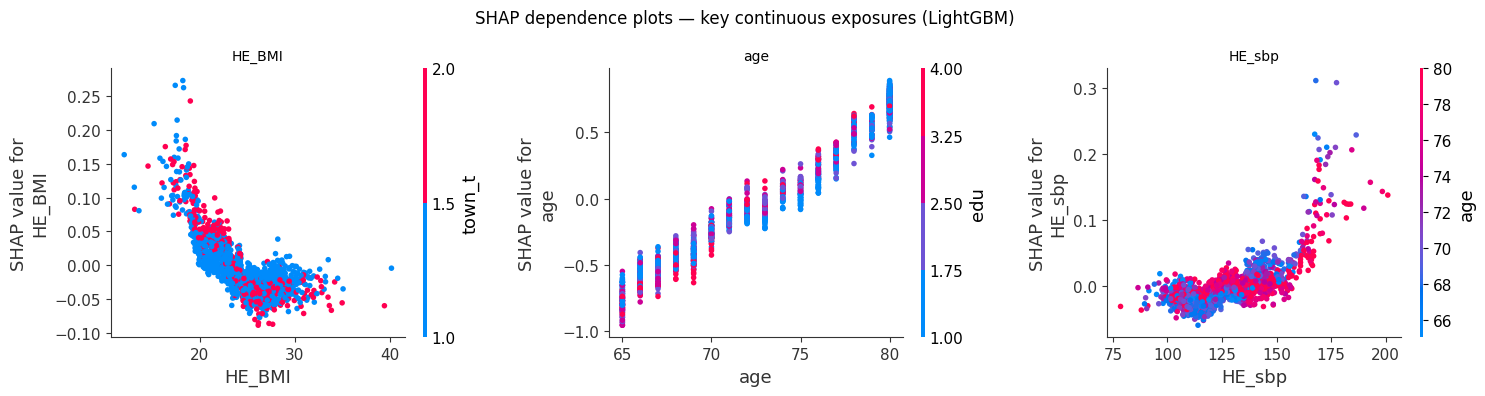

In [77]:
# ── SHAP dependence plots — key continuous exposures ─────────────────────────
# The beeswarm shows magnitude; these show the *shape* of the dose-response curve
# (linear vs. threshold) and the strongest interacting feature via the colour
# gradient (auto-selected by SHAP).
# NOTE: for Logistic Regression the SHAP-vs-feature relationship is linear BY
# CONSTRUCTION (shap = coef × scaled value), so these curves are straight lines and
# add little beyond the odds ratios. They are most informative for the tree models.
dep_feats = [f for f in ['HE_HbA1c', 'HE_crea', 'HE_BMI', 'age', 'HE_sbp']
             if f in feature_cols]

ncol = 3
nrow = int(np.ceil(len(dep_feats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))
axes = np.atleast_1d(axes).ravel()

for ax, feat in zip(axes, dep_feats):
    shap.dependence_plot(
        feat, shap_values, X_test_imp,
        feature_names=feature_cols, ax=ax, show=False,
    )
    ax.set_title(feat, fontsize=10)

for ax in axes[len(dep_feats):]:
    ax.set_visible(False)

fig.suptitle(f'SHAP dependence plots — key continuous exposures ({best_name})',
             fontsize=12)
plt.tight_layout()
plt.show()


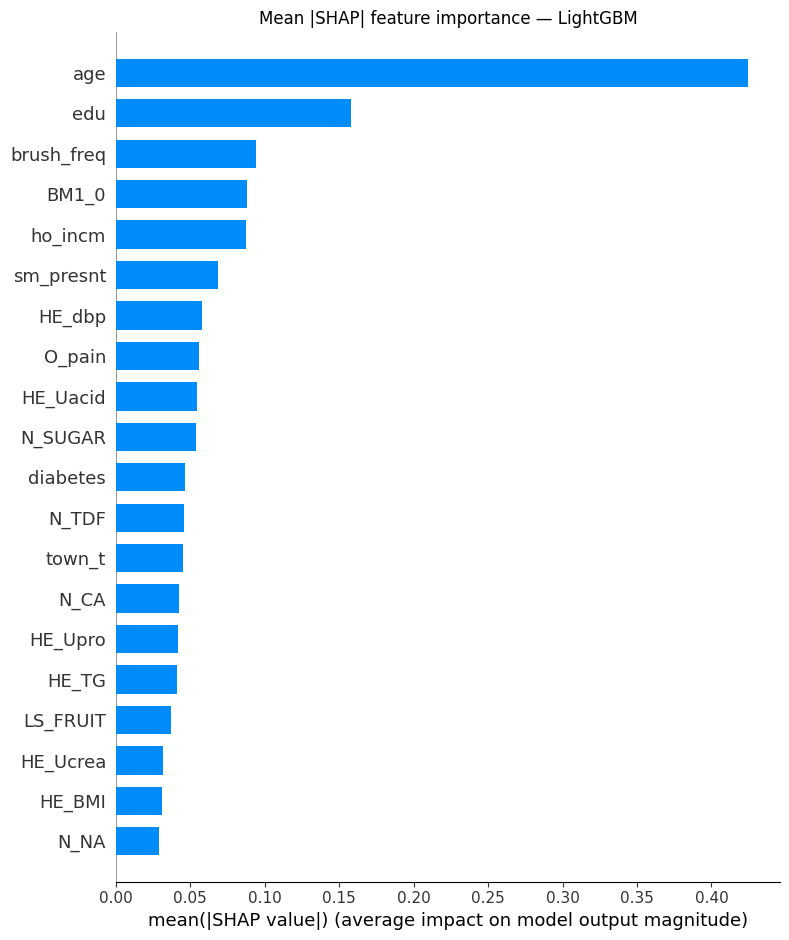

In [78]:
# ── Global feature importance — mean |SHAP| bar plot ─────────────────────────
# Clean global ranking; pairs with the beeswarm as the standard two-panel figure.
shap.summary_plot(
    shap_values, X_test_imp,
    feature_names=feature_cols,
    plot_type='bar', max_display=20, show=False,
)
plt.title(f'Mean |SHAP| feature importance — {best_name}', fontsize=12)
plt.tight_layout()
plt.show()


<h2 style="color:#FFA500";> 9. Visualisation — Confusion Matrix, Feature Importance, ROC Curve </h2>

Diagnostic plots for the best tuned model on the **test set**, built with `sklearn` + `matplotlib` (no PyCaret). The confusion matrix and feature importance use the top model from §8; §9.1 overlays the ROC curves of all tuned models.

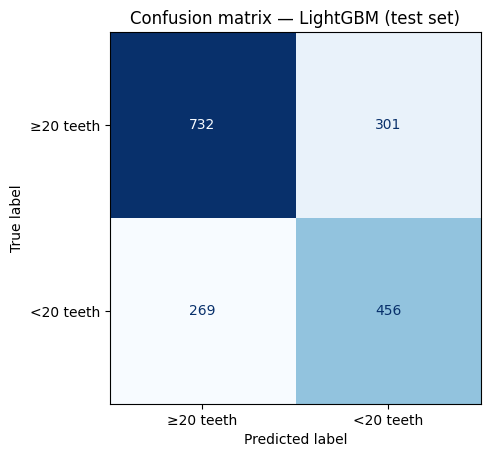

In [79]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Confusion matrix for the best model (default 0.5 threshold) on the test set
y_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(
    cm, display_labels=['≥20 teeth', '<20 teeth']
).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix — {best_name} (test set)')
plt.tight_layout()
plt.show()


Youden's J threshold (OOF train): 0.5315
  OOF Sensitivity: 0.5860
  OOF Specificity: 0.7338


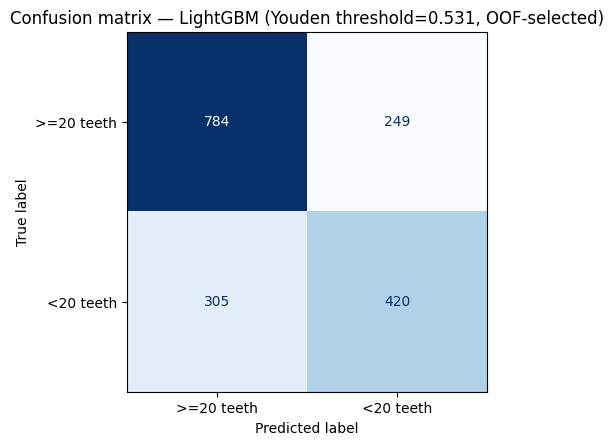

In [80]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, confusion_matrix
from sklearn.model_selection import cross_val_predict

# Threshold selection via OOF probabilities — avoids optimising on the test set
oof_proba = cross_val_predict(best_model, X_train, y_train,
                              cv=cv, method='predict_proba')[:, 1]
fpr_oof, tpr_oof, thresh_oof = roc_curve(y_train, oof_proba)
j_scores = tpr_oof + (1 - fpr_oof) - 1
best_idx  = j_scores.argmax()
THRESHOLD = float(thresh_oof[best_idx])

print(f"Youden's J threshold (OOF train): {THRESHOLD:.4f}")
print(f"  OOF Sensitivity: {tpr_oof[best_idx]:.4f}")
print(f"  OOF Specificity: {1 - fpr_oof[best_idx]:.4f}")

# Apply frozen threshold once to the held-out test set
proba_best = best_model.predict_proba(X_test)[:, 1]
preds_t = (proba_best >= THRESHOLD).astype(int)
cm_t = confusion_matrix(y_test, preds_t)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(
    cm_t, display_labels=['>=20 teeth', '<20 teeth']
).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix — {best_name} (Youden threshold={THRESHOLD:.3f}, OOF-selected)')
plt.tight_layout()
plt.show()

MCC threshold (OOF train):  0.5315
Best OOF MCC score:          0.3232


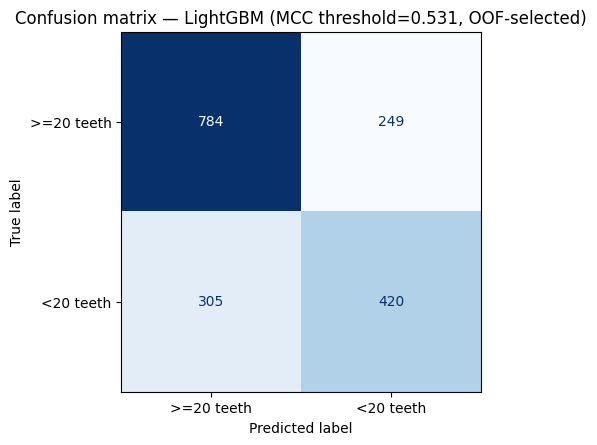

In [81]:
from sklearn.metrics import matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay

# Reuse OOF probabilities and thresholds from cell above
mcc_scores = [
    matthews_corrcoef(y_train, (oof_proba >= t).astype(int))
    for t in thresh_oof
]

best_mcc_idx  = int(max(range(len(mcc_scores)), key=lambda i: mcc_scores[i]))
MCC_THRESHOLD = float(thresh_oof[best_mcc_idx])
best_mcc_oof  = mcc_scores[best_mcc_idx]

print(f"MCC threshold (OOF train):  {MCC_THRESHOLD:.4f}")
print(f"Best OOF MCC score:          {best_mcc_oof:.4f}")

# Apply frozen threshold once to the held-out test set
preds_mcc = (proba_best >= MCC_THRESHOLD).astype(int)
cm_mcc = confusion_matrix(y_test, preds_mcc)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(
    cm_mcc, display_labels=['>=20 teeth', '<20 teeth']
).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix — {best_name} (MCC threshold={MCC_THRESHOLD:.3f}, OOF-selected)')
plt.tight_layout()
plt.show()

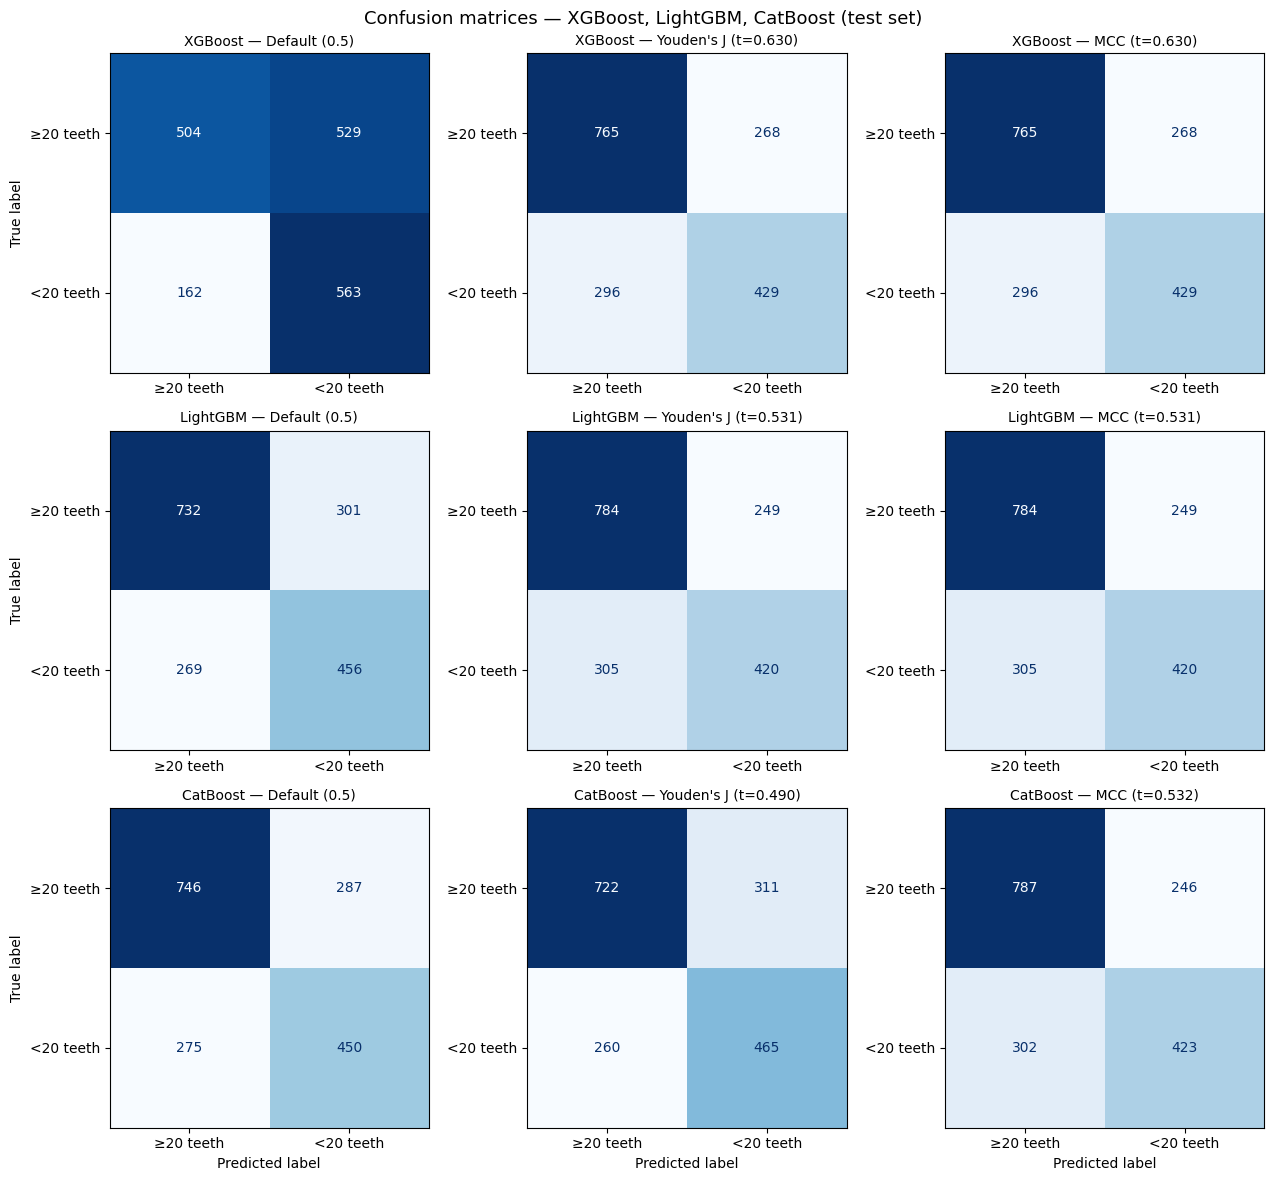

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, matthews_corrcoef
from sklearn.model_selection import cross_val_predict

target_models   = ['XGBoost', 'LightGBM', 'CatBoost']
col_labels      = ["Default (0.5)", "Youden's J", 'MCC']

fig, axes = plt.subplots(3, 3, figsize=(13, 12))

for row, name in enumerate(target_models):
    model      = fitted_models[name]
    proba_test = model.predict_proba(X_test)[:, 1]

    # OOF probabilities on train — threshold must not touch test set
    oof_p = cross_val_predict(model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    fpr_oof, tpr_oof, thresh_oof = roc_curve(y_train, oof_p)

    # Youden's J threshold
    j_scores      = tpr_oof + (1 - fpr_oof) - 1
    youden_thresh = float(thresh_oof[j_scores.argmax()])

    # MCC threshold
    mcc_scores  = [matthews_corrcoef(y_train, (oof_p >= t).astype(int)) for t in thresh_oof]
    mcc_thresh  = float(thresh_oof[int(max(range(len(mcc_scores)), key=lambda i: mcc_scores[i]))])

    for col, (thresh, label) in enumerate(zip([0.5, youden_thresh, mcc_thresh], col_labels)):
        preds = (proba_test >= thresh).astype(int)
        cm    = confusion_matrix(y_test, preds)
        ConfusionMatrixDisplay(cm, display_labels=['≥20 teeth', '<20 teeth']).plot(
            ax=axes[row, col], cmap='Blues', colorbar=False)
        t_str = '' if thresh == 0.5 else f' (t={thresh:.3f})'
        axes[row, col].set_title(f'{name} — {label}{t_str}', fontsize=10)
        if col != 0:
            axes[row, col].set_ylabel('')
        if row != 2:
            axes[row, col].set_xlabel('')

plt.suptitle('Confusion matrices — XGBoost, LightGBM, CatBoost (test set)', fontsize=13)
plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 9.1 ROC Curve Comparison </h3>

Overlay the ROC curves of all tuned models on the test set for side-by-side AUC comparison.

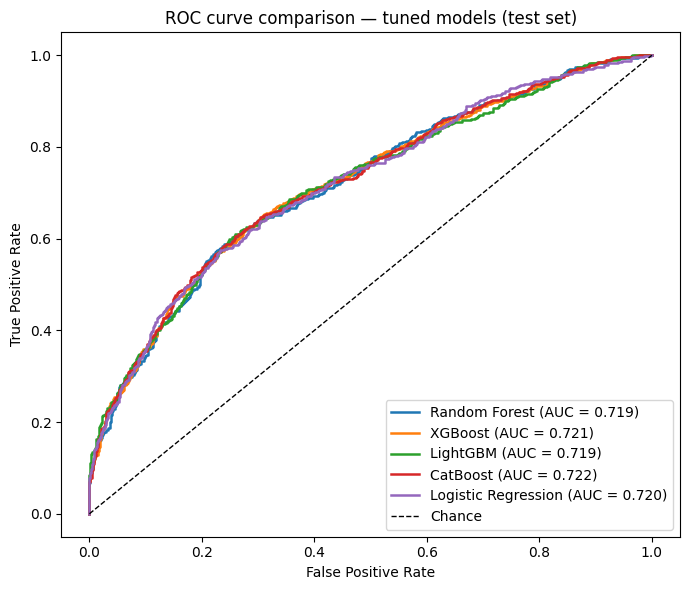

In [83]:
from sklearn.metrics import roc_curve, auc

# All tuned models on one ROC plot (test set) for comparison
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, linewidth=1.8, label=f'{name} (AUC = {auc(fpr, tpr):.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC curve comparison — tuned models (test set)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


<h3 style="color:yellow";> 9.2 AUPRC Curve  </h3>



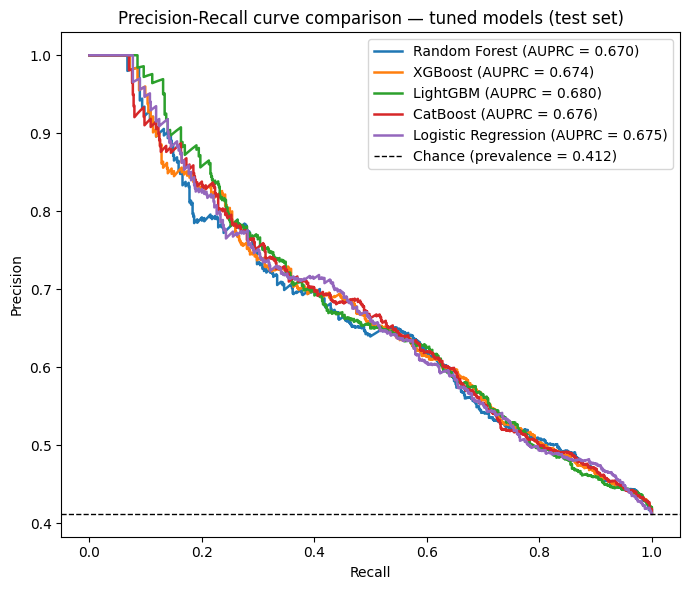

In [84]:
from sklearn.metrics import precision_recall_curve, average_precision_score

baseline = y_test.mean()   # random classifier AUPRC = positive class prevalence

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    ax.plot(rec, prec, linewidth=1.8, label=f'{name} (AUPRC = {ap:.3f})')

ax.axhline(baseline, color='k', linestyle='--', linewidth=1,
           label=f'Chance (prevalence = {baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve comparison — tuned models (test set)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


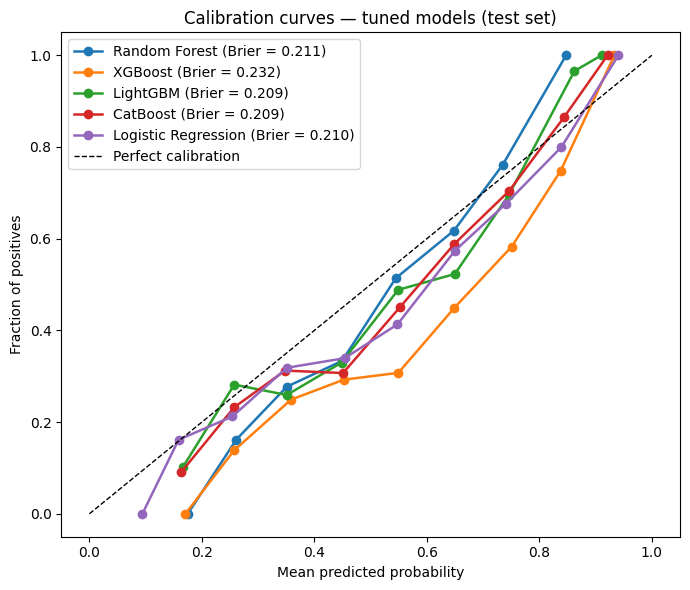

In [85]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(7, 6))

for name, model in fitted_models.items():
    proba = model.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, proba)
    prob_true, prob_pred = calibration_curve(y_test, proba, n_bins=10, strategy='uniform')
    ax.plot(prob_pred, prob_true, marker='o', linewidth=1.8,
            label=f'{name} (Brier = {brier:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Fraction of positives')
ax.set_title('Calibration curves — tuned models (test set)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

<h2 style="color:#FFA500;"> 10. Inferential Analysis — Multivariable Logistic Regression </h2>

The sections above answer *"what predicts tooth loss?"* (prediction). The research question is different — *"which clinical, behavioral, and socioeconomic factors affect tooth loss **independently of age and sex**?"* That is an **explanatory** question, answered with logistic regression reporting **adjusted odds ratios (aOR)**.

- **Outcome:** `O_TC_` (1 = tooth loss, < 20 teeth)
- **Core exposures:** eGFR (CKD), diabetes (combined criterion), income (`ho_incm`), education (`edu`)
- **Additional exposures:** occupation, marital status, urbanicity (`town_t`), smoking, alcohol (`BD1`), physical activity, stress (`BP1`), BMI, systolic & diastolic blood pressure, uric acid, proteinuria (`HE_Upro`), urine creatinine (`HE_Ucrea`), oral pain (`O_pain`), triglycerides (`HE_TG`), dietary intakes (calcium, sodium, protein, fiber, vegetable, fruit, sugar)
- **Adjustment covariates:** age, sex
- **Excluded from §10:** `HE_glu` (collinear with diabetes/HbA1c), `region` (17-category nominal — no valid linear encoding), `HE_wc` (collinear with BMI), `HE_chol` / `HE_HDL_st2` (not significant), `L_BR_FQ` (non-monotonic crude rate), and the comorbidity flags for atopic dermatitis / asthma / rheumatoid arthritis (no measurable independent link)
- **No SMOTE** — resampling distorts class proportions and biases odds ratios.
- **Complete-case** analysis (rows with any missing model variable are dropped).

In [86]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Build modelling frame from the cleaned df_subset.
# sex is now retained in df_subset after eGFR derivation, so no need to pull from original df.
reg = df_subset.copy()
reg['sex_female'] = (reg['sex'] == 2).astype(float)
# 'diabetes' column already present — combined criterion (DE1_dg == 1 OR HbA1c >= 6.5%) created in §4.3

# Binary recodes: KNHANES codes 2=No → recode to 0 for intuitive OR direction (1=yes vs 0=no)
for col in ['BD1', 'marri_1', 'town_t']:
    reg[col] = reg[col].map({1: 1, 2: 0})
# BP1 (perceived stress): original 1=very stressed → 4=not at all; reverse so higher = more stressed
reg['BP1'] = 5 - reg['BP1']

exposures = [
    # core (existing)
    'eGFR', 'diabetes', 'ho_incm', 'edu',
    # additional SES
    'occp', 'marri_1', 'town_t',
    # lifestyle
    'sm_presnt', 'BD1', 'pa_aerobic', 'BP1',
    # clinical
    'HE_BMI', 'HE_sbp', 'HE_dbp', 'HE_Uacid',
    # urinalysis
    'HE_Upro', 'HE_Ucrea',
    # dental
    'O_pain',
    # lipids
    'HE_TG',
    # dietary
    'N_CA', 'N_NA', 'N_PROT', 'N_TDF', 'LS_VEG1', 'LS_FRUIT', 'N_SUGAR',
]
# region     excluded: 17-category nominal — no linear ordering, not valid as continuous
# HE_chol   excluded: not significant (p=0.90), no independent tooth loss mechanism
# HE_HDL_st2 excluded: not significant (p=0.73), no independent tooth loss mechanism
# HE_wc     excluded: collinear with HE_BMI (VIF 5.81); HE_BMI retained
# L_BR_FQ   excluded: non-monotonic crude rate (1=29.8%, 2=18.8%, 3=15.2%, 4=21.4%) — linear coefficient uninterpretable

covariates = ['age', 'sex_female']
model_vars = exposures + covariates

# complete-case; NO SMOTE (would bias the odds ratios)
# Survey design columns pulled alongside model vars for weighted inference
design_cols = ['wt_itvex', 'year', 'kstrata', 'psu']
m = (reg[['O_TC_'] + design_cols + model_vars]
     .replace([np.inf, -np.inf], np.nan).dropna())

# KNHANES integrated weight for pooled waves: annual weight / #years (5)
m['svy_wt'] = m['wt_itvex'] / 5.0
# strata/PSU codes repeat across waves -> make globally unique per (year, stratum/PSU)
# survey internals coerce strata/PSU with as.numeric() -> string IDs become NA
# and blow up the variance estimate (Inf SE, p=1.0). Use integer codes instead.
m['svy_strata'] = pd.factorize(
    m['year'].astype(int).astype(str) + '_' + m['kstrata'].astype(int).astype(str)
)[0] + 1
m['svy_psu'] = pd.factorize(
    m['year'].astype(int).astype(str) + '_'
    + m['kstrata'].astype(int).astype(str) + '_'
    + m['psu'].astype(str)
)[0] + 1

print(f"Complete-case n = {len(m)}  |  tooth-loss prevalence = {m['O_TC_'].mean():.1%}")

# occp is nominal (1-7) -> dummy-encode with occp==1 (Mgr/Prof) as reference,
# replacing the single linear occp term so each occupation gets its own OR
if 'occp' in model_vars:
    occp_d = pd.get_dummies(m['occp'].round().astype(int), prefix='occp',
                            drop_first=True, dtype=float)
    m = pd.concat([m, occp_d], axis=1)
    model_vars = [c for c in model_vars if c != 'occp'] + list(occp_d.columns)

# Drop zero-variance columns (inestimable in any GLM)
# std < 1e-8 catches near-constant float columns that nunique() misses
zero_var = [c for c in model_vars if m[c].nunique() <= 1 or m[c].std() < 1e-8]
if zero_var:
    print(f"Dropping zero-variance columns (inestimable): {zero_var}")
    model_vars = [c for c in model_vars if c not in zero_var]

# Full complex-survey logistic regression via R's survey::svyglm
# Handles strata + PSU + weights with Taylor linearization — fully design-based SEs
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr

survey_pkg = importr('survey')

# Pass model frame + design columns to R
r_cols = ['O_TC_', 'svy_wt', 'svy_strata', 'svy_psu'] + model_vars

# Narrow context: only convert the DataFrame going into R
with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
    r_df = pandas2ri.py2rpy(m[r_cols])

# R function calls outside the converter context so their return values
# (R S3 objects) are NOT auto-converted back to Python lists
# Strata with a single PSU can't estimate variance by default; 'adjust'
# centers the unit at the overall mean (Lumley's recommended handling)
ro.r('options(survey.lonely.psu = "adjust")')
svy_design = survey_pkg.svydesign(
    ids=ro.Formula('~svy_psu'),
    strata=ro.Formula('~svy_strata'),
    weights=ro.Formula('~svy_wt'),
    data=r_df
)

# quasibinomial recommended by Lumley for survey-weighted binary outcomes
formula_str = 'O_TC_ ~ ' + ' + '.join(model_vars)
svyfit = survey_pkg.svyglm(
    ro.Formula(formula_str),
    design=svy_design,
    family=ro.r('quasibinomial(link="logit")')
)

# Narrow context: only convert the result matrices back to pandas
coef_mat = ro.r('summary')(svyfit).rx2('coefficients')
ci_mat = ro.r('confint')(svyfit)
with localconverter(ro.default_converter + numpy2ri.converter + pandas2ri.converter):
    coef_df = pd.DataFrame(
        pandas2ri.rpy2py(coef_mat),
        index=list(ro.r('rownames')(coef_mat)),
        columns=['Estimate', 'SE', 't', 'p-value']
    )
    ci_df = pd.DataFrame(
        pandas2ri.rpy2py(ci_mat),
        index=list(ro.r('rownames')(ci_mat)),
        columns=['CI 2.5%', 'CI 97.5%']
    )

or_table = pd.DataFrame({
    'aOR':      np.exp(coef_df['Estimate']),
    'CI 2.5%':  np.exp(ci_df['CI 2.5%']),
    'CI 97.5%': np.exp(ci_df['CI 97.5%']),
    'p-value':  coef_df['p-value']
})

print("\n=== Adjusted odds ratios (survey::svyglm, Taylor linearization) ===")
print(or_table.round(4).to_string())

Complete-case n = 5793  |  tooth-loss prevalence = 40.0%

=== Adjusted odds ratios (survey::svyglm, Taylor linearization) ===
                aOR  CI 2.5%  CI 97.5%  p-value
(Intercept)  0.0067   0.0011    0.0419   0.0000
eGFR         1.0018   0.9963    1.0073   0.5166
diabetes     1.3473   1.1600    1.5648   0.0001
ho_incm      0.9084   0.8478    0.9734   0.0065
edu          0.8187   0.7617    0.8800   0.0000
marri_1      0.6723   0.3688    1.2254   0.1945
town_t       0.7103   0.6104    0.8265   0.0000
sm_presnt    1.6874   1.3205    2.1562   0.0000
BD1          1.0487   0.8865    1.2406   0.5782
pa_aerobic   0.9875   0.8457    1.1531   0.8734
BP1          0.9908   0.9052    1.0844   0.8403
HE_BMI       0.9825   0.9616    1.0038   0.1061
HE_sbp       0.9979   0.9923    1.0035   0.4622
HE_dbp       0.9930   0.9837    1.0024   0.1447
HE_Uacid     1.0603   1.0010    1.1230   0.0462
HE_Upro      1.2033   1.0388    1.3938   0.0137
HE_Ucrea     1.0001   0.9986    1.0015   0.9278
O_pain    

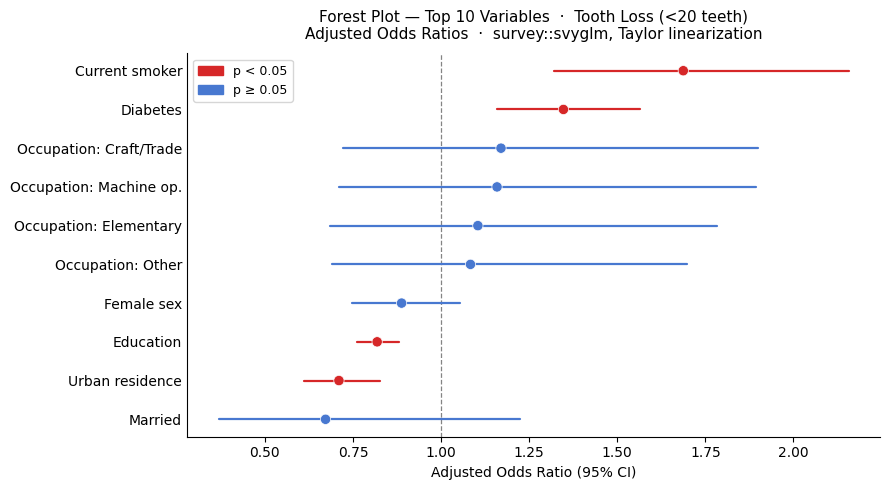

In [87]:
# ── Forest plot: top 10 variables by effect size ───────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

label_map = {
    'sm_presnt':  'Current smoker',
    'occp_4':     'Occupation: Craft/Trade',
    'occp_5':     'Occupation: Machine op.',
    'diabetes':   'Diabetes',
    'occp_6':     'Occupation: Elementary',
    'sex_female': 'Female sex',
    'town_t':     'Urban residence',
    'marri_1':    'Married',
    'edu':        'Education',
    'occp_7':     'Occupation: Other',
}

top10_vars = list(label_map.keys())
plot_df = or_table.loc[or_table.index.intersection(top10_vars)].copy()
plot_df = plot_df.sort_values('aOR')

labels = [label_map[v] for v in plot_df.index]
y      = np.arange(len(plot_df))
sig    = plot_df['p-value'] < 0.05
colors = ['#d62728' if s else '#4878d0' for s in sig]  # red=sig, blue=ns

fig, ax = plt.subplots(figsize=(9, 5))

for i, (lo, hi, col) in enumerate(zip(plot_df['CI 2.5%'], plot_df['CI 97.5%'], colors)):
    ax.plot([lo, hi], [i, i], color=col, linewidth=1.6, solid_capstyle='round')

ax.scatter(plot_df['aOR'], y, color=colors, s=55, zorder=3,
           edgecolors='white', linewidths=0.5)
ax.axvline(1.0, color='#333333', linewidth=0.9, linestyle='--', alpha=0.6, zorder=0)

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)
ax.set_xlabel('Adjusted Odds Ratio (95% CI)', fontsize=10)
ax.set_title(
    'Forest Plot — Top 10 Variables  ·  Tooth Loss (<20 teeth)\n'
    'Adjusted Odds Ratios  ·  survey::svyglm, Taylor linearization',
    fontsize=11, pad=10
)

ax.legend(
    handles=[mpatches.Patch(color='#d62728', label='p < 0.05'),
             mpatches.Patch(color='#4878d0', label='p ≥ 0.05')],
    fontsize=9, framealpha=0.8
)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

<h3 style="color:yellow";> 10.1 Collinearity Check (VIF) </h3>

eGFR is derived using age, so we verify it is not collinear with the `age` covariate. VIF must be computed **with an intercept** — omitting it inflates VIF for variables whose mean is far from zero. Rule of thumb: VIF > 5 warrants attention, > 10 is serious.

In [88]:
Xc = sm.add_constant(m[model_vars].astype(float), has_constant='add')
vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])],
    index=Xc.columns
).drop('const')
print("VIF (with intercept):")
print(vif.sort_values(ascending=False).round(2).to_string())

VIF (with intercept):
occp_7        10.04
occp_6         6.50
occp_4         3.80
occp_3         3.30
occp_5         2.97
N_TDF          2.57
N_PROT         2.26
N_SUGAR        1.96
N_NA           1.90
N_CA           1.88
sex_female     1.87
HE_dbp         1.81
HE_sbp         1.78
occp_2         1.66
age            1.58
edu            1.52
eGFR           1.48
HE_Uacid       1.44
ho_incm        1.36
LS_FRUIT       1.28
HE_Ucrea       1.26
town_t         1.22
HE_Upro        1.18
BD1            1.18
sm_presnt      1.16
HE_BMI         1.12
HE_TG          1.11
diabetes       1.11
LS_VEG1        1.10
pa_aerobic     1.08
BP1            1.04
marri_1        1.02
O_pain         1.01


<h3 style="color:yellow";> 10.2 Correlation Heatmap — Regression Features </h3>

The visual companion to the VIF table above. VIF gives the number; this shows the
full pairwise correlation picture among the complete-case regression features, so
you can see at a glance that no two predictors are strongly collinear.

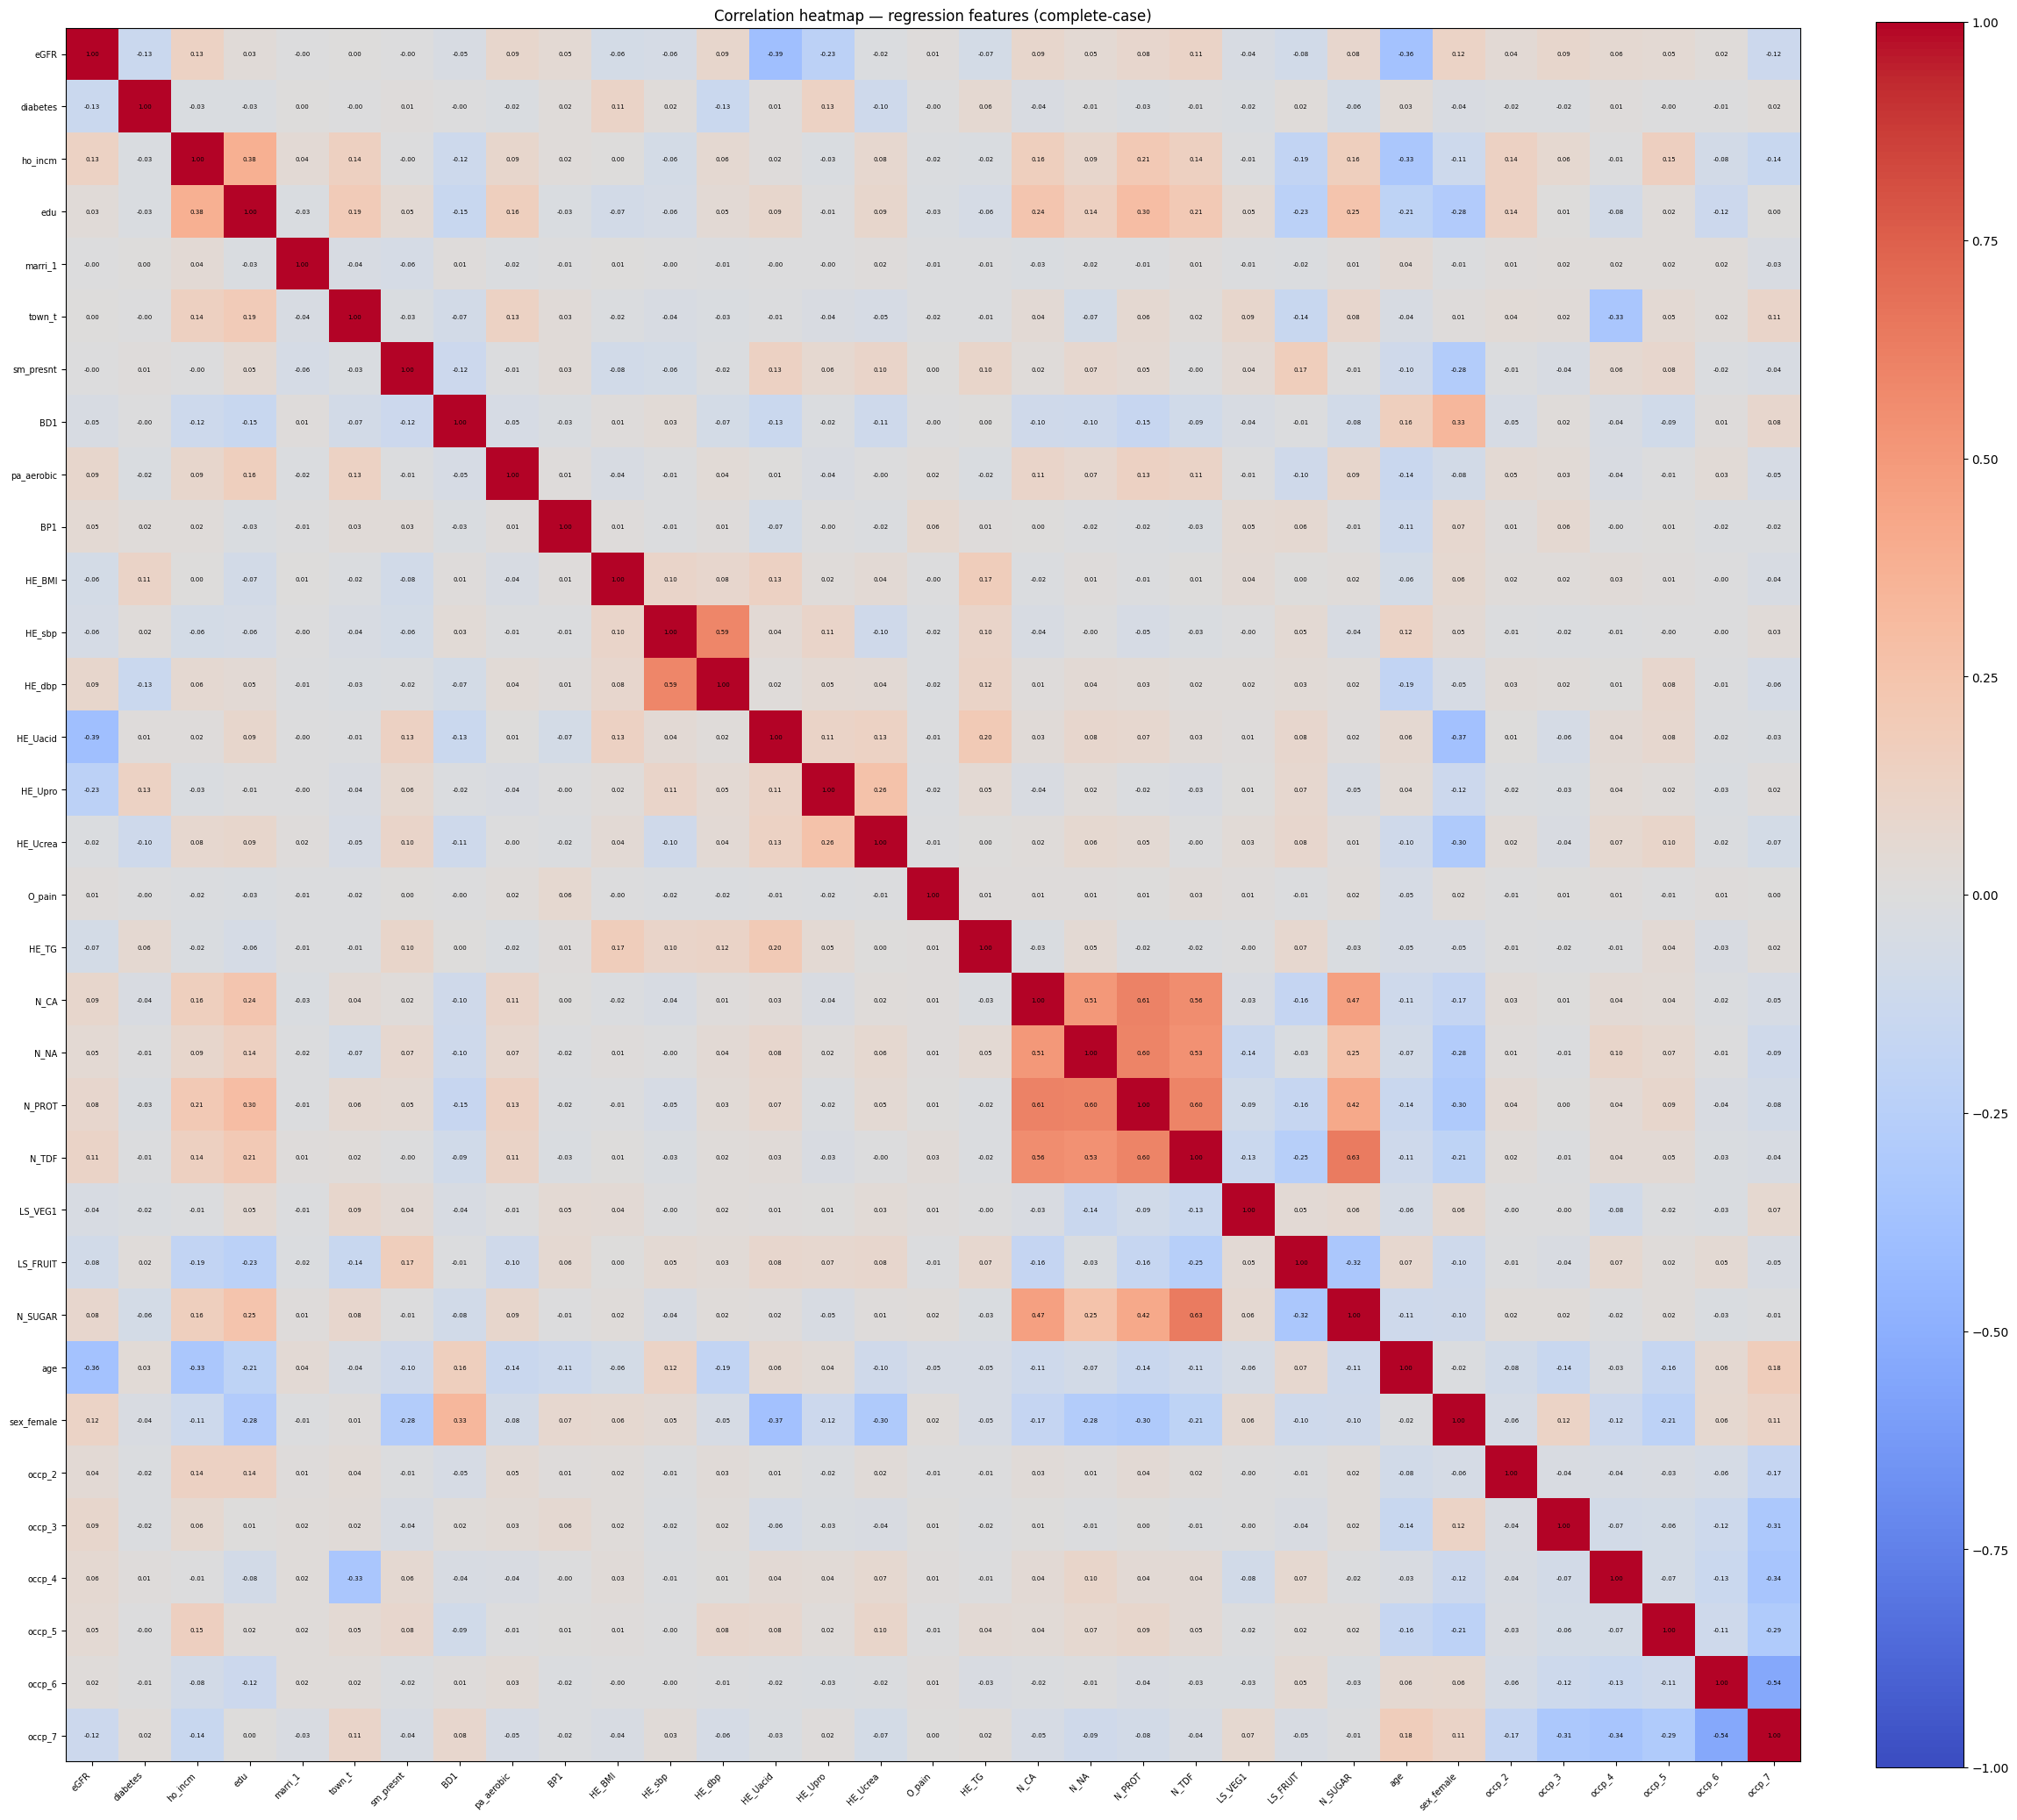

In [89]:
corr = m[model_vars].corr()

n = len(model_vars)
fig, ax = plt.subplots(figsize=(max(12, n * 0.7), max(10, n * 0.65)))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(model_vars, rotation=45, ha='right', fontsize=7)
ax.set_yticklabels(model_vars, fontsize=7)

for i in range(n):
    for j in range(n):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=5)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Correlation heatmap — regression features (complete-case)')
plt.tight_layout()
plt.show()

Top 10 correlated pairs:
  N_TDF                x N_SUGAR               r = 0.635
  N_CA                 x N_PROT                r = 0.605
  N_PROT               x N_TDF                 r = 0.598
  N_NA                 x N_PROT                r = 0.598
  HE_sbp               x HE_dbp                r = 0.589
  N_CA                 x N_TDF                 r = 0.555
  occp_6               x occp_7                r = -0.541
  N_NA                 x N_TDF                 r = 0.534
  N_CA                 x N_NA                  r = 0.508
  N_CA                 x N_SUGAR               r = 0.467


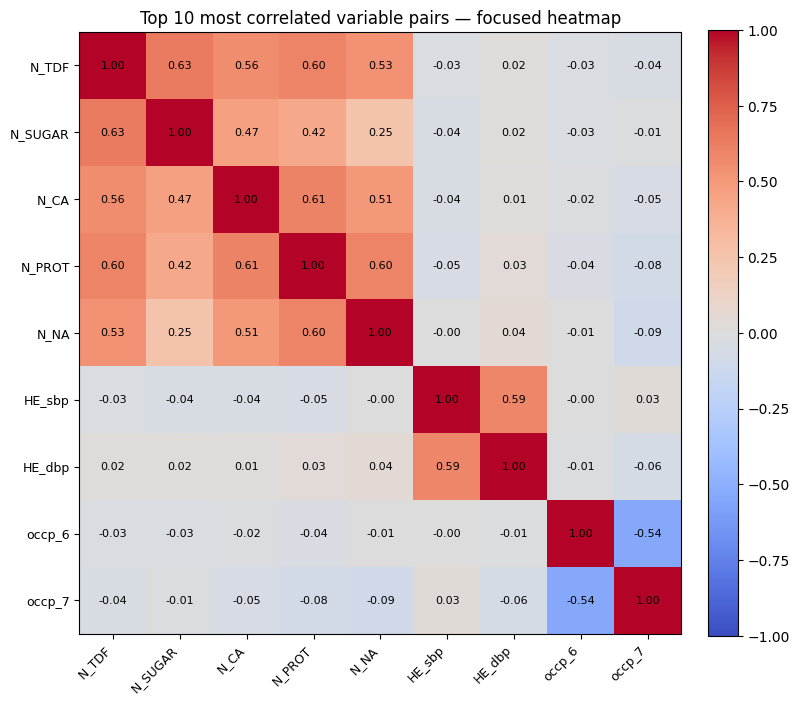

In [90]:
# Top 10 most correlated variable pairs (by absolute correlation, excluding self-correlation)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
top10_pairs = (upper.stack()
                    .abs()
                    .sort_values(ascending=False)
                    .head(10))

print("Top 10 correlated pairs:")
for (v1, v2), val in top10_pairs.items():
    print(f"  {v1:20s} x {v2:20s}  r = {corr.loc[v1, v2]:.3f}")

# Focused heatmap: unique variables involved in the top 10 pairs
top_vars = list(dict.fromkeys([v for pair in top10_pairs.index for v in pair]))
corr_sub = corr.loc[top_vars, top_vars]

n2 = len(top_vars)
fig, ax = plt.subplots(figsize=(max(8, n2 * 0.9), max(7, n2 * 0.85)))
im = ax.imshow(corr_sub, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(n2))
ax.set_yticks(range(n2))
ax.set_xticklabels(top_vars, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(top_vars, fontsize=9)

for i in range(n2):
    for j in range(n2):
        ax.text(j, i, f"{corr_sub.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Top 10 most correlated variable pairs — focused heatmap")
plt.tight_layout()
plt.show()